This notebook shows the discrimination power of the likelihood metric against the current chi2 at particle identification

In [1]:
import numpy as np
import math
import pickle
import pandas as pd
import uproot as uproot
import matplotlib.pyplot as plt
import gc
import sys
sys.path.insert(0, "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana")
# from analysis_village.plot_style import sbnd_style

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)



In [2]:
with pd.HDFStore("/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/output_MC_collab_LL.df", mode="r") as store:
    keys = store.keys()
    print(keys)

['/evt_0', '/hdr_0', '/histgenevtdf_0', '/histpotdf_0', '/mcnu_0', '/pot_0', '/split']


In [14]:
df = pd.read_hdf("/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana/output_MC_largeTest_LL.df", key='/evt_0')
# # df = df[df["total_nhits_proton"] > 14]
# muondf = df[np.abs(df["truth_pdg"]) == 13]
# piondf = df[np.abs(df["truth_pdg"]) == 211]
# protondf = df[df["truth_pdg"] == 2212]
df = df[df["slc", "is_clear_cosmic"] == 0]
df = df[df["pfp", "trk", "truth", "p", "cont_tpc"] == 1]


/tmp/ipykernel_1150730/3408046138.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  df = df[df["slc", "is_clear_cosmic"] == 0]
/tmp/ipykernel_1150730/3408046138.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  df = df[df["pfp", "trk", "truth", "p", "cont_tpc"] == 1]


In [3]:
df.head()

slc  \
                                                      is_clear_cosmic   
                                                                        
                                                                        
                                                                        
                                                                        
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                   
1        1     0              0                                     0   
                              1                                     0   
         3     0              0                                     0   
                              1                                     0   
         4     0              0                                     0   

                                                                              \
                                                          vertex               
                                                               x           y   
                                                                               
                                                                               
                                                                               
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                          
1        1     0              0                       -68.975815  124.859596   
                              1                       -68.975815  124.859596   
         3     0              0                       -52.697365    4.298021   
                              1                       -52.697365    4.298021   
         4     0              0                       -46.268570 -186.258606   

                                                                        \
                                                                  self   
                                                                z        
                                                                         
                                                                         
                                                                         
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                    
1        1     0              0                        217.167191   73   
                              1                        217.167191   73   
         3     0              0                        399.908264   28   
                              1                        399.908264   28   
         4     0              0                        148.239227   39   

                                                                               \
                                                         tmatch                 
                                                            eff       pur idx   
                                                                                
                                                                                
                                                                                
__ntuple entry rec.slc..index rec.slc.reco.pfp..index                           
1        1     0              0                        0.980509  0.560783   0   
                              1                        0.980509  0.560783   0   
         3     0              0                        0.656768  0.876566   1   
                              1                        0.656768  0.876566   1   
         4     0              0                        0.967384  0.665963   0   

                                                                              \
                                                      producer          nuid   
                                                               crlongtrkdiry   
                                                                               
                                              

In [15]:
p_df = df[df["pfp", "trk", "truth", "p", "pdg"] == 2212]
mu_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 13]
pi_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 211]
print(f"Protons: {len(p_df)}, Muons: {len(mu_df)}, Pions: {len(pi_df)}")


Protons: 7086, Muons: 1789, Pions: 942


/tmp/ipykernel_1150730/556601378.py:1: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_df = df[df["pfp", "trk", "truth", "p", "pdg"] == 2212]
/tmp/ipykernel_1150730/556601378.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 13]
/tmp/ipykernel_1150730/556601378.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_df = df[np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == 211]


/tmp/ipykernel_1150730/3593872833.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist(p_df["pfp", "trk", "llpid", "ell_p"] - p_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
/tmp/ipykernel_1150730/3593872833.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist(mu_df["pfp", "trk", "llpid", "ell_p"] - mu_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Muons', color='red', histtype='step')
/tmp/ipykernel_1150730/3593872833.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist(pi_df["pfp", "trk", "llpid", "ell_p"] - pi_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Pions', color='green', histtype='step')
/tmp/ipykernel_1150730/3593872833.py:12: PerformanceWarning: indexing past lexsort depth may impact perfor

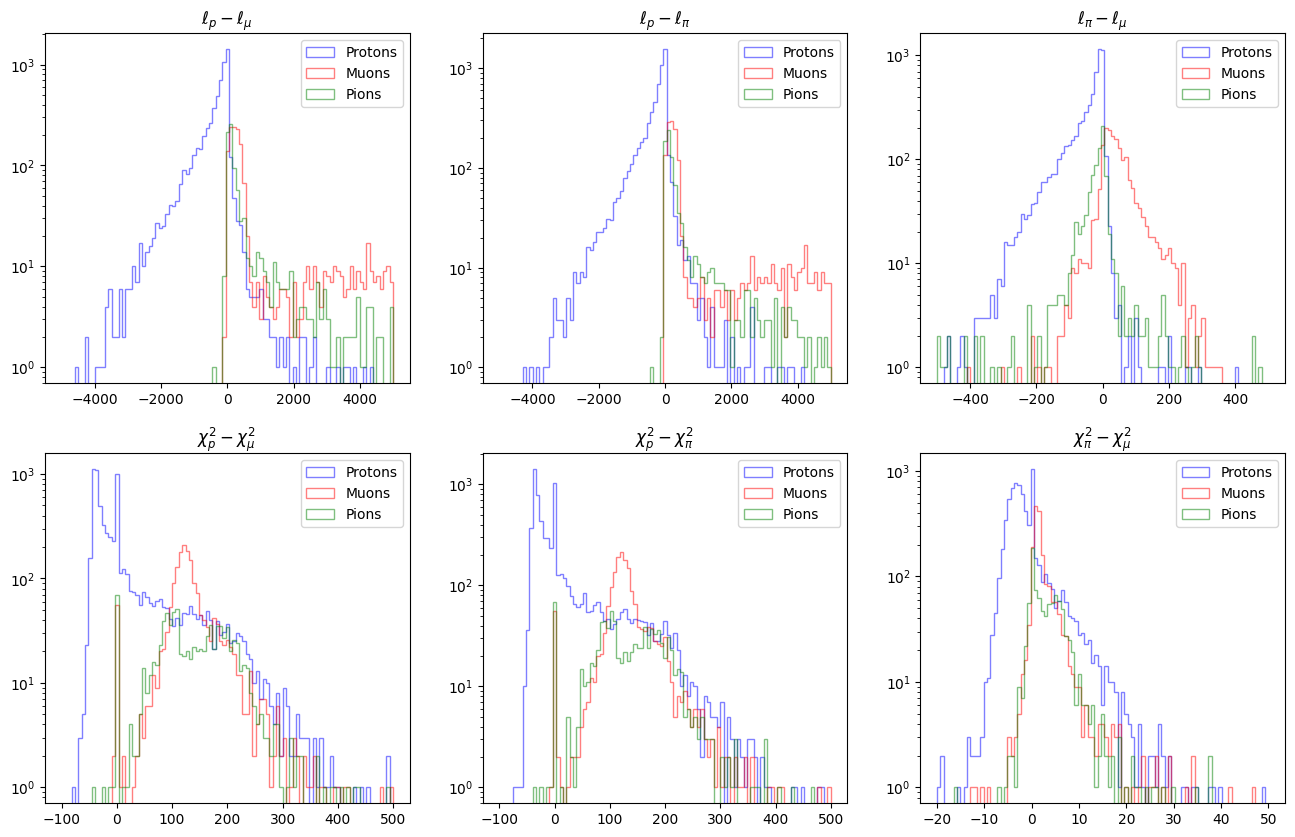

In [17]:
fig, ax = plt.subplots(2,3, figsize=(16, 10))
ax = ax.flatten()
log=True

ax[0].hist(p_df["pfp", "trk", "llpid", "ell_p"] - p_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[0].hist(mu_df["pfp", "trk", "llpid", "ell_p"] - mu_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[0].hist(pi_df["pfp", "trk", "llpid", "ell_p"] - pi_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[0].legend()
ax[0].set_title(f"$\ell_p - \ell_\mu$ ")


ax[1].hist(p_df["pfp", "trk", "llpid", "ell_p"] - p_df["pfp", "trk", "llpid", "ell_pi"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[1].hist(mu_df["pfp", "trk", "llpid", "ell_p"] - mu_df["pfp", "trk", "llpid", "ell_pi"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[1].hist(pi_df["pfp", "trk", "llpid", "ell_p"] - pi_df["pfp", "trk", "llpid", "ell_pi"], bins=np.linspace(-5000, 5000, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[1].legend()
ax[1].set_title(f"$\ell_p - \ell_\pi$ ")


ax[2].hist(p_df["pfp", "trk", "llpid", "ell_pi"] - p_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-500, 500, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[2].hist(mu_df["pfp", "trk", "llpid", "ell_pi"] - mu_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-500, 500, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[2].hist(pi_df["pfp", "trk", "llpid", "ell_pi"] - pi_df["pfp", "trk", "llpid", "ell_mu"], bins=np.linspace(-500, 500, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[2].legend()
ax[2].set_title(f"$\ell_\pi - \ell_\mu$ ")


ax[3].hist(p_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - p_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[3].hist(mu_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - mu_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[3].hist(pi_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - pi_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[3].legend()
ax[3].set_title(f"$\chi^2_p - \chi^2_\mu$ ")

ax[4].hist(p_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - p_df["pfp", "trk","chi2pid","I2", "chi2_pion"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[4].hist(mu_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - mu_df["pfp", "trk","chi2pid","I2", "chi2_pion"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[4].hist(pi_df["pfp", "trk","chi2pid","I2", "chi2_proton"] - pi_df["pfp", "trk","chi2pid","I2", "chi2_pion"], bins=np.linspace(-100, 500, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[4].legend()
ax[4].set_title(f"$\chi^2_p - \chi^2_\pi$ ")

ax[5].hist(p_df["pfp", "trk","chi2pid","I2", "chi2_pion"] - p_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-20, 50, 100), alpha=0.5, label='Protons', color='blue', histtype='step')
ax[5].hist(mu_df["pfp", "trk","chi2pid","I2", "chi2_pion"] - mu_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-20, 50, 100), alpha=0.5, label='Muons', color='red', histtype='step')
ax[5].hist(pi_df["pfp", "trk","chi2pid","I2", "chi2_pion"] - pi_df["pfp", "trk","chi2pid","I2", "chi2_muon"], bins=np.linspace(-20, 50, 100), alpha=0.5, label='Pions', color='green', histtype='step')
ax[5].legend()
ax[5].set_title(f"$\chi^2_\pi - \chi^2_\mu$ ")

if log:
    for i in range(6):
        ax[i].set_yscale('log')
plt.show()  

/tmp/ipykernel_1150730/2263204449.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Blues')
/tmp/ipykernel_1150730/2263204449.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[1].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Reds')
/tmp/ipykernel_1150730/2263204449.py:14: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[2].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Greens')
/tmp/ipykernel_1150730/2263204449.py:19: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[3].hist2d(p_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], p_df["pfp", "trk", "chi2pid", "I2", "chi2

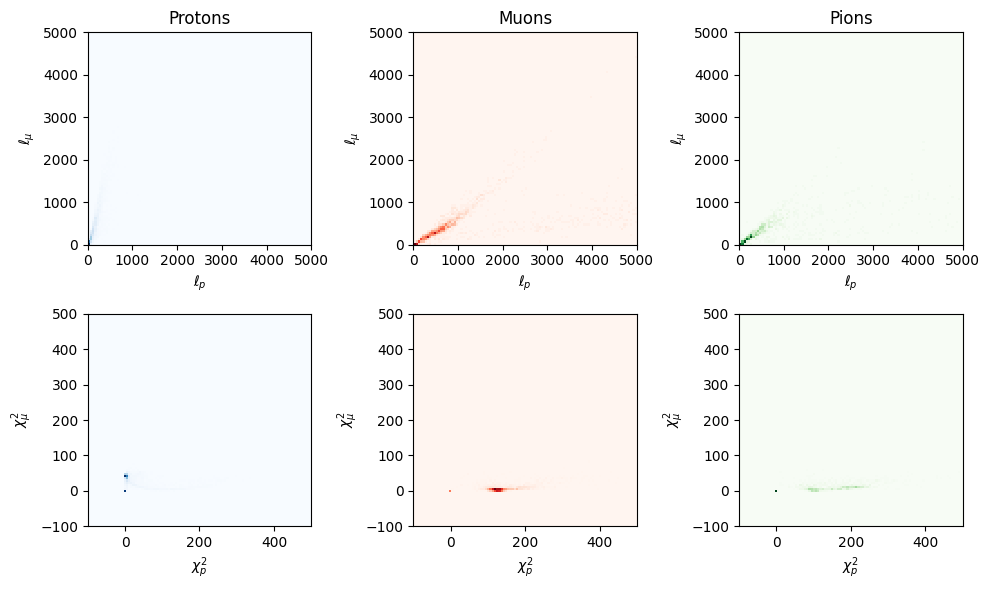

In [18]:
fig, ax = plt.subplots(2,3,figsize=(10, 6))
ax=ax.flatten()

ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Blues')
ax[0].set_xlabel("$\ell_p$")
ax[0].set_ylabel("$\ell_\mu$")
ax[0].set_title("Protons")

ax[1].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Reds')
ax[1].set_xlabel("$\ell_p$")
ax[1].set_ylabel("$\ell_\mu$")
ax[1].set_title("Muons")

ax[2].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[0, 5000], [0, 5000]], cmap='Greens')
ax[2].set_xlabel("$\ell_p$")
ax[2].set_ylabel("$\ell_\mu$")
ax[2].set_title("Pions")

ax[3].hist2d(p_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], p_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-100, 500], [-100, 500]], cmap='Blues')
ax[3].set_xlabel("$\chi^2_p$")
ax[3].set_ylabel("$\chi^2_\mu$")

ax[4].hist2d(mu_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], mu_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-100, 500], [-100, 500]], cmap='Reds')
ax[4].set_xlabel("$\chi^2_p$")
ax[4].set_ylabel("$\chi^2_\mu$")
ax[5].hist2d(pi_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], pi_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-100, 500], [-100, 500]], cmap='Greens')
ax[5].set_xlabel("$\chi^2_p$")
ax[5].set_ylabel("$\chi^2_\mu$")

plt.tight_layout()
plt.show()

/tmp/ipykernel_1150730/1689864628.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
/tmp/ipykernel_1150730/1689864628.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
/tmp/ipykernel_1150730/1689864628.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  ax[0].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
/tmp/ipykernel_1150730/1689864628.py:15: PerformanceWarning: indexing past lexsort depth may impact

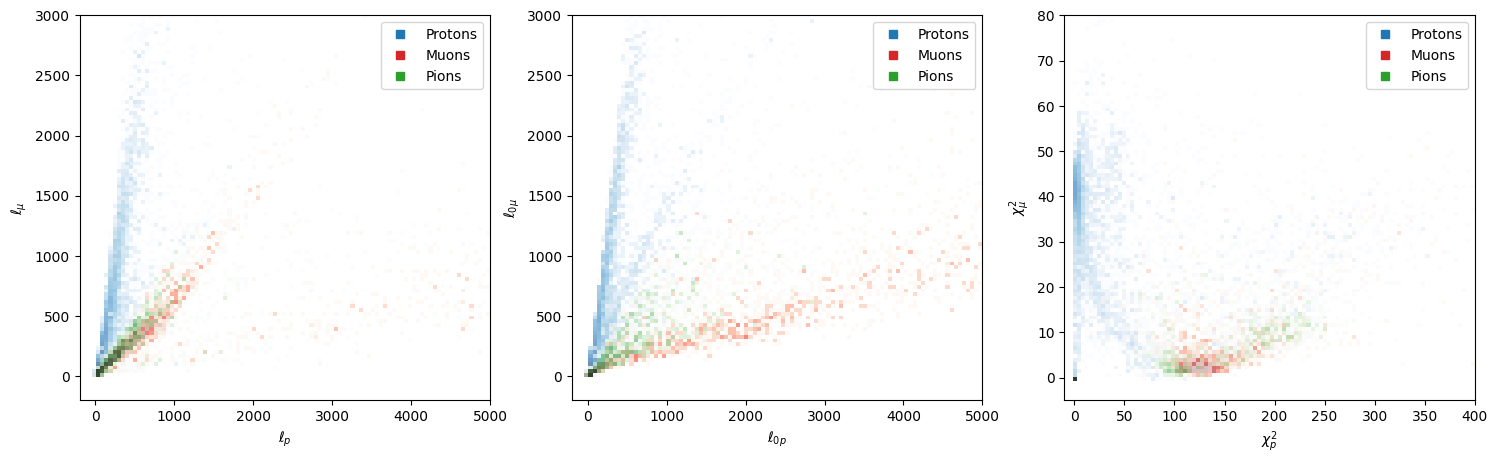

In [19]:
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(1,3,figsize=(18, 5))

ax[0].hist2d(p_df["pfp", "trk", "llpid", "ell_p"], p_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
ax[0].hist2d(mu_df["pfp", "trk", "llpid", "ell_p"], mu_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
ax[0].hist2d(pi_df["pfp", "trk", "llpid", "ell_p"], pi_df["pfp", "trk", "llpid", "ell_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
ax[0].plot([], [], 's', color='tab:blue', label='Protons')
ax[0].plot([], [], 's', color='tab:red', label='Muons')
ax[0].plot([], [], 's', color='tab:green', label='Pions')
ax[0].legend()
ax[0].set_xlabel("$\ell_p$")
ax[0].set_ylabel("$\ell_\mu$")

ax[1].hist2d(p_df["pfp", "trk", "llpid", "ell0_p"], p_df["pfp", "trk", "llpid", "ell0_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
ax[1].hist2d(mu_df["pfp", "trk", "llpid", "ell0_p"], mu_df["pfp", "trk", "llpid", "ell0_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
ax[1].hist2d(pi_df["pfp", "trk", "llpid", "ell0_p"], pi_df["pfp", "trk", "llpid", "ell0_mu"], bins=100, range=[[-200, 5000], [-200, 3000]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
ax[1].plot([], [], 's', color='tab:blue', label='Protons')
ax[1].plot([], [], 's', color='tab:red', label='Muons')
ax[1].plot([], [], 's', color='tab:green', label='Pions')
ax[1].legend()
ax[1].set_xlabel("$\ell_{0p}$")
ax[1].set_ylabel("$\ell_{0\mu}$")


ax[2].hist2d(p_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], p_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-10, 400], [-5, 80]], cmap='Blues', cmin=1, alpha=0.6, norm=LogNorm())
ax[2].hist2d(mu_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], mu_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-10, 400], [-5, 80]], cmap='Reds', cmin=1, alpha=0.6, norm=LogNorm())
ax[2].hist2d(pi_df["pfp", "trk", "chi2pid", "I2", "chi2_proton"], pi_df["pfp", "trk", "chi2pid", "I2", "chi2_muon"], bins=100, range=[[-10, 400], [-5, 80]], cmap='Greens', cmin=1, alpha=0.6, norm=LogNorm())
ax[2].plot([], [], 's', color='tab:blue', label='Protons')
ax[2].plot([], [], 's', color='tab:red', label='Muons')
ax[2].plot([], [], 's', color='tab:green', label='Pions')
ax[2].legend()
ax[2].set_xlabel("$\chi^2_p$")
ax[2].set_ylabel("$\chi^2_\mu$")

# plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/1937425854.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_ok  = p_df[p_df["pfp", "trk", "llpid", "ell_mu"].notna() & (p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
/tmp/ipykernel_1150730/1937425854.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_ok = mu_df[mu_df["pfp", "trk", "llpid", "ell_mu"].notna() & (mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
/tmp/ipykernel_1150730/1937425854.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_ok = pi_df[pi_df["pfp", "trk", "llpid", "ell_mu"].notna() & (pi_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
/tmp/ipykernel_1150730/1937425854.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  sig = p_ok["pfp", "trk", "llpid", "ell_p"] - p_ok["pfp", "trk", "llpid", "ell_mu"]
/tmp/ipykernel_1150730/1937425854.py:10: PerformanceWarning: indexing past lexsort depth may impact perform

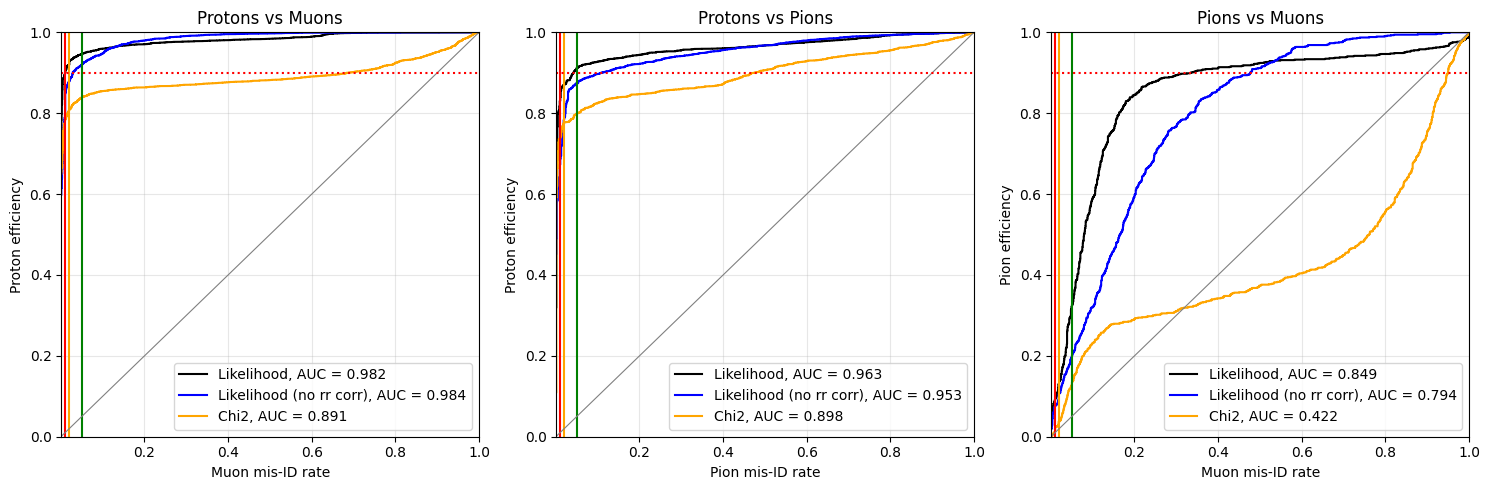

In [30]:
# only keep tracks where both the likelihood and the chi2 worked
p_ok  = p_df[p_df["pfp", "trk", "llpid", "ell_mu"].notna() & (p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
mu_ok = mu_df[mu_df["pfp", "trk", "llpid", "ell_mu"].notna() & (mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]
pi_ok = pi_df[pi_df["pfp", "trk", "llpid", "ell_mu"].notna() & (pi_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] > 0)]

fig, ax = plt.subplots(1,3,figsize=(15, 5))

# Protons vs Muons, likelihood
sig = p_ok["pfp", "trk", "llpid", "ell_p"] - p_ok["pfp", "trk", "llpid", "ell_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell_p"] - mu_ok["pfp", "trk", "llpid", "ell_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[0].plot(bkg_eff, sig_eff, color='black', label=f"Likelihood, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
# Protons vs Muons, likelihood0
sig = p_ok["pfp", "trk", "llpid", "ell0_p"] - p_ok["pfp", "trk", "llpid", "ell0_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell0_p"] - mu_ok["pfp", "trk", "llpid", "ell0_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[0].plot(bkg_eff, sig_eff, color='blue', label=f"Likelihood (no rr corr), AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

# Protons vs Muons, chi2
sig = p_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - p_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
bkg = mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[0].plot(bkg_eff, sig_eff, color='orange', label=f"Chi2, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
ax[0].set_title("Protons vs Muons")
ax[0].set_xlabel("Muon mis-ID rate")
ax[0].set_ylabel("Proton efficiency")
ax[0].vlines([0.01, 0.02, 0.05], 0,1, colors=['red', 'orange', 'green'])


# Protons vs Pions, likelihood
sig = p_ok["pfp", "trk", "llpid", "ell_p"] - p_ok["pfp", "trk", "llpid", "ell_pi"]
bkg = pi_ok["pfp", "trk", "llpid", "ell_p"] - pi_ok["pfp", "trk", "llpid", "ell_pi"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[1].plot(bkg_eff, sig_eff, color='black', label=f"Likelihood, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

sig = p_ok["pfp", "trk", "llpid", "ell0_p"] - p_ok["pfp", "trk", "llpid", "ell0_pi"]
bkg = pi_ok["pfp", "trk", "llpid", "ell0_p"] - pi_ok["pfp", "trk", "llpid", "ell0_pi"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[1].plot(bkg_eff, sig_eff, color='blue', label=f"Likelihood (no rr corr), AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

# Protons vs Pions, chi2
sig = p_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - p_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"]
bkg = pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_proton"] - pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[1].plot(bkg_eff, sig_eff, color='orange', label=f"Chi2, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
ax[1].set_title("Protons vs Pions")
ax[1].set_xlabel("Pion mis-ID rate")
ax[1].set_ylabel("Proton efficiency")
ax[1].vlines([0.01, 0.02, 0.05], 0,1, colors=['red', 'orange', 'green'])

# Pions vs Muons, likelihood
sig = pi_ok["pfp", "trk", "llpid", "ell_pi"] - pi_ok["pfp", "trk", "llpid", "ell_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell_pi"] - mu_ok["pfp", "trk", "llpid", "ell_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[2].plot(bkg_eff, sig_eff, color='black', label=f"Likelihood, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

sig = pi_ok["pfp", "trk", "llpid", "ell0_pi"] - pi_ok["pfp", "trk", "llpid", "ell0_mu"]
bkg = mu_ok["pfp", "trk", "llpid", "ell0_pi"] - mu_ok["pfp", "trk", "llpid", "ell0_mu"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[2].plot(bkg_eff, sig_eff, color='blue', label=f"Likelihood (no rr corr), AUC = {np.trapz(sig_eff, bkg_eff):.3f}")

# Pions vs Muons, chi2
sig = pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"] - pi_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
bkg = mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_pion"] - mu_ok["pfp", "trk", "chi2pid", "I2", "chi2_muon"]
cuts = np.sort(np.concatenate([sig, bkg]))
sig_eff = [np.mean(sig <= c) for c in cuts]
bkg_eff = [np.mean(bkg <= c) for c in cuts]
ax[2].plot(bkg_eff, sig_eff, color='orange', label=f"Chi2, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
ax[2].set_title("Pions vs Muons")
ax[2].set_xlabel("Muon mis-ID rate")
ax[2].set_ylabel("Pion efficiency")
ax[2].vlines([0.01, 0.02, 0.05], 0,1, colors=['red', 'orange', 'green'])

for k in range(3):
    ax[k].plot([0, 1], [0, 1], color='gray', linewidth=0.8)
    ax[k].axhline(0.9, color='red', linestyle=':')
    ax[k].set_xlim(0.001, 1)
    # ax[k].set_xscale("log")
    ax[k].set_ylim(0, 1)
    ax[k].grid(alpha=0.3)
    ax[k].legend()

plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/1530449805.py:2: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_ll_bad   = p_df["pfp", "trk", "llpid", "ell_mu"].isna()
/tmp/ipykernel_1150730/1530449805.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_chi_bad  = p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
/tmp/ipykernel_1150730/1530449805.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_ll_bad  = mu_df["pfp", "trk", "llpid", "ell_mu"].isna()
/tmp/ipykernel_1150730/1530449805.py:5: PerformanceWarning: indexing past lexsort depth may impact performance.
  mu_chi_bad = mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
/tmp/ipykernel_1150730/1530449805.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_ll_bad  = pi_df["pfp", "trk", "llpid", "ell_mu"].isna()
/tmp/ipykernel_1150730/1530449805.py:7: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_chi_

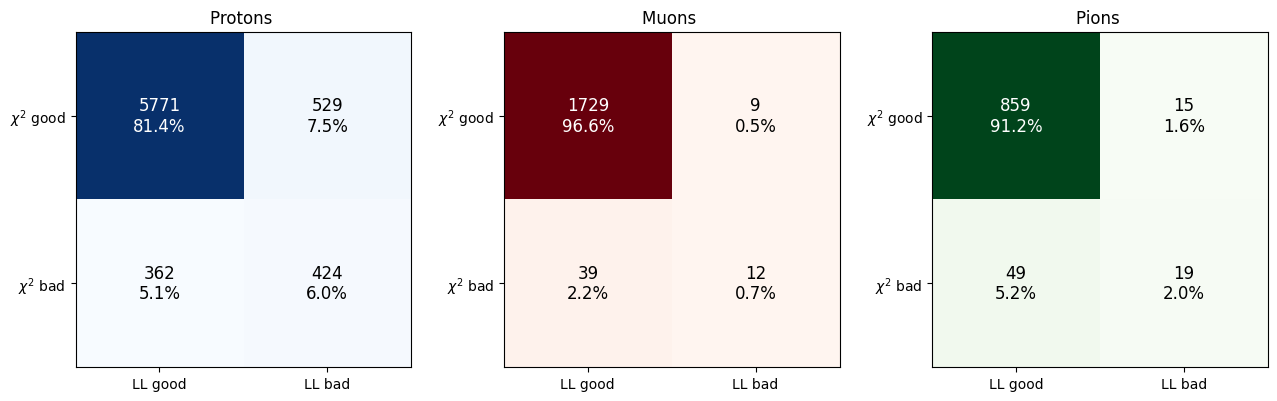

In [31]:
# True = that PID failed for this track
p_ll_bad   = p_df["pfp", "trk", "llpid", "ell_mu"].isna()
p_chi_bad  = p_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
mu_ll_bad  = mu_df["pfp", "trk", "llpid", "ell_mu"].isna()
mu_chi_bad = mu_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0
pi_ll_bad  = pi_df["pfp", "trk", "llpid", "ell_mu"].isna()
pi_chi_bad = pi_df["pfp", "trk", "chi2pid", "I2", "pid_ndof"] == 0

# rows = chi2 (good, bad), columns = llpid (good, bad)
p_mat  = np.array([[np.sum(~p_chi_bad & ~p_ll_bad),   np.sum(~p_chi_bad & p_ll_bad)],
                   [np.sum(p_chi_bad & ~p_ll_bad),    np.sum(p_chi_bad & p_ll_bad)]])
mu_mat = np.array([[np.sum(~mu_chi_bad & ~mu_ll_bad), np.sum(~mu_chi_bad & mu_ll_bad)],
                   [np.sum(mu_chi_bad & ~mu_ll_bad),  np.sum(mu_chi_bad & mu_ll_bad)]])
pi_mat = np.array([[np.sum(~pi_chi_bad & ~pi_ll_bad), np.sum(~pi_chi_bad & pi_ll_bad)],
                   [np.sum(pi_chi_bad & ~pi_ll_bad),  np.sum(pi_chi_bad & pi_ll_bad)]])

fig, ax = plt.subplots(1,3,figsize=(13, 4))

ax[0].imshow(p_mat, cmap='Blues')
ax[0].set_title(f"Protons ")
ax[1].imshow(mu_mat, cmap='Reds')
ax[1].set_title(f"Muons ")
ax[2].imshow(pi_mat, cmap='Greens')
ax[2].set_title(f"Pions ")

for k, mat in enumerate([p_mat, mu_mat, pi_mat]):
    for i in range(2):
        for j in range(2):
            ax[k].text(j, i, f"{mat[i, j]}\n{100 * mat[i, j] / mat.sum():.1f}%", ha='center', va='center', fontsize=12, color='white' if mat[i, j] > mat.max() / 2 else 'black')
    ax[k].set_xticks([0, 1])
    ax[k].set_xticklabels(["LL good", "LL bad"])
    ax[k].set_yticks([0, 1])
    ax[k].set_yticklabels(["$\\chi^2$ good", "$\\chi^2$ bad"])

plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/2452625986.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_cont = p_df[(p_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & p_df["pfp", "trk", "llpid", "ell_p"].notna()]
/tmp/ipykernel_1150730/2452625986.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_true = (p_cont["pfp", "trk", "truth", "p", "startE"] - m_p) * 1000  # MeV
/tmp/ipykernel_1150730/2452625986.py:12: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_range = p_cont["pfp", "trk", "rangeP", "p_proton"]
/tmp/ipykernel_1150730/2452625986.py:17: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_corr = np.interp(p_cont["pfp", "trk", "len"] + p_cont["pfp", "trk", "llpid", "dl_p"], table["range"], table["ke"])  # MeV
/tmp/ipykernel_1150730/2452625986.py:23: PerformanceWarning: indexing past lexsort depth may impact performance.
  stopped = p_cont["pfp", "trk", "truth", "p", "end_process"

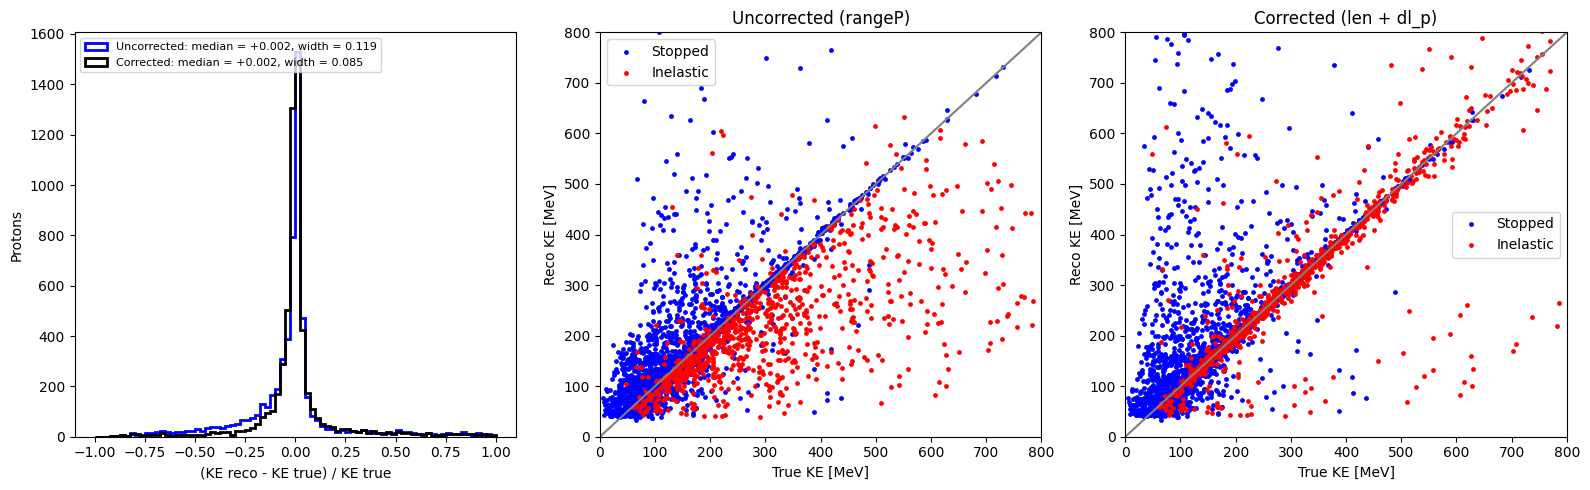

In [22]:
from makedf import llpid

# true protons that are contained in the TPC and have a likelihood fit
p_cont = p_df[(p_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & p_df["pfp", "trk", "llpid", "ell_p"].notna()]

m_p = 0.938272  # GeV

# true KE
ke_true = (p_cont["pfp", "trk", "truth", "p", "startE"] - m_p) * 1000  # MeV

# uncorrected: CAF range momentum
p_range = p_cont["pfp", "trk", "rangeP", "p_proton"]
ke_uncorr = (np.sqrt(p_range**2 + m_p**2) - m_p) * 1000  # MeV

# corrected: range = reco length + dl_p, turned into KE with the llpid range table
table = llpid._ke_table("p")
ke_corr = np.interp(p_cont["pfp", "trk", "len"] + p_cont["pfp", "trk", "llpid", "dl_p"], table["range"], table["ke"])  # MeV

res_uncorr = (ke_uncorr - ke_true) / ke_true
res_corr = (ke_corr - ke_true) / ke_true

# how the true proton ended
stopped = p_cont["pfp", "trk", "truth", "p", "end_process"] == 54   # hIoni: ranged out and stopped
inel    = p_cont["pfp", "trk", "truth", "p", "end_process"] == 7    # protonInelastic: interacted before stopping

fig, ax = plt.subplots(1,3,figsize=(16, 5))

ax[0].hist(res_uncorr, bins=np.linspace(-1, 1, 81), histtype='step', linewidth=2, color='blue', label=f"Uncorrected: median = {np.median(res_uncorr):+.3f}, width = {(np.percentile(res_uncorr, 84) - np.percentile(res_uncorr, 16)) / 2:.3f}")
ax[0].hist(res_corr, bins=np.linspace(-1, 1, 81), histtype='step', linewidth=2, color='black', label=f"Corrected: median = {np.median(res_corr):+.3f}, width = {(np.percentile(res_corr, 84) - np.percentile(res_corr, 16)) / 2:.3f}")
ax[0].set_xlabel("(KE reco - KE true) / KE true")
ax[0].set_ylabel("Protons")
ax[0].legend(loc='upper left', fontsize=8)

ax[1].scatter(ke_true[stopped], ke_uncorr[stopped], s=6, color='blue', label="Stopped")
ax[1].scatter(ke_true[inel], ke_uncorr[inel], s=6, color='red', label="Inelastic")
ax[1].plot([0, 800], [0, 800], color='gray')
ax[1].set_xlim(0, 800)
ax[1].set_ylim(0, 800)
ax[1].set_xlabel("True KE [MeV]")
ax[1].set_ylabel("Reco KE [MeV]")
ax[1].set_title("Uncorrected (rangeP)")
ax[1].legend()

ax[2].scatter(ke_true[stopped], ke_corr[stopped], s=6, color='blue', label="Stopped")
ax[2].scatter(ke_true[inel], ke_corr[inel], s=6, color='red', label="Inelastic")
ax[2].plot([0, 800], [0, 800], color='gray')
ax[2].set_xlim(0, 800)
ax[2].set_ylim(0, 800)
ax[2].set_xlabel("True KE [MeV]")
ax[2].set_ylabel("Reco KE [MeV]")
ax[2].set_title("Corrected (len + dl_p)")
ax[2].legend()

plt.tight_layout()
plt.show()


/tmp/ipykernel_1150730/1929644183.py:4: PerformanceWarning: indexing past lexsort depth may impact performance.
  pi_cont = pi_df[(pi_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & pi_df["pfp", "trk", "llpid", "ell_pi"].notna()]
/tmp/ipykernel_1150730/1929644183.py:9: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_true = (pi_cont["pfp", "trk", "truth", "p", "startE"] - m_pi) * 1000  # MeV
/tmp/ipykernel_1150730/1929644183.py:12: PerformanceWarning: indexing past lexsort depth may impact performance.
  p_range = pi_cont["pfp", "trk", "rangeP", "p_pion"]
/tmp/ipykernel_1150730/1929644183.py:17: PerformanceWarning: indexing past lexsort depth may impact performance.
  ke_corr = np.interp(pi_cont["pfp", "trk", "len"] + pi_cont["pfp", "trk", "llpid", "dl_pi"], table["range"], table["ke"])  # MeV
/tmp/ipykernel_1150730/1929644183.py:23: PerformanceWarning: indexing past lexsort depth may impact performance.
  stopped = (pi_cont["pfp", "trk", "truth", "p", "e

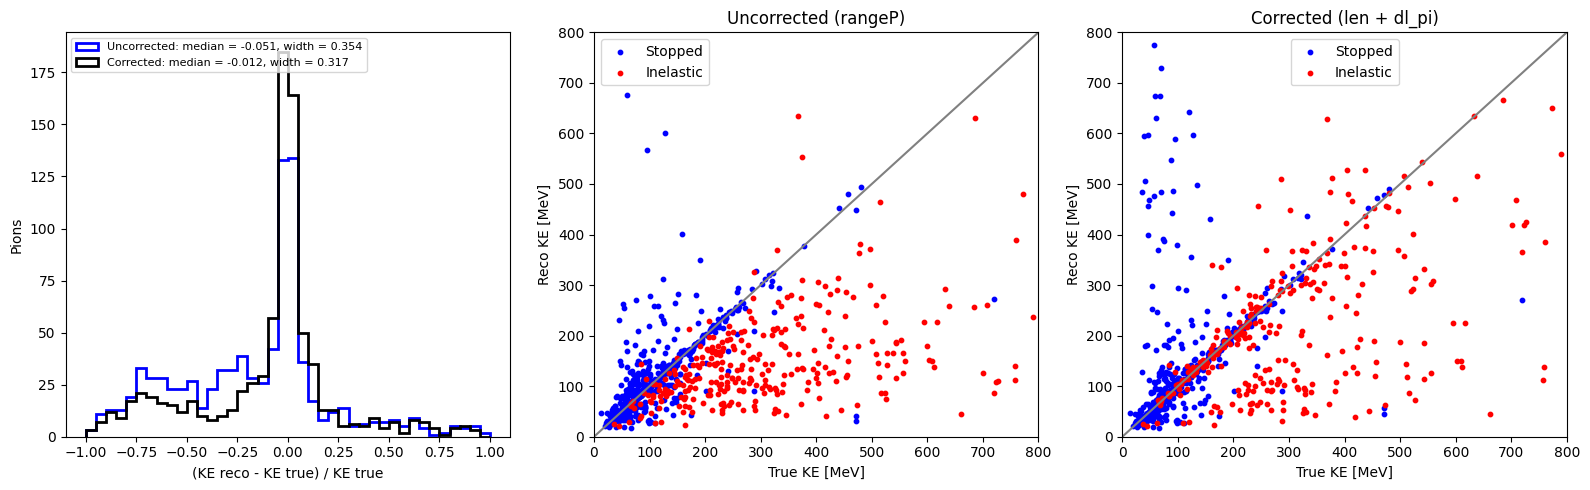

In [23]:
from makedf import llpid

# true pions that are contained in the TPC and have a likelihood fit
pi_cont = pi_df[(pi_df["pfp", "trk", "truth", "p", "cont_tpc"] == 1) & pi_df["pfp", "trk", "llpid", "ell_pi"].notna()]

m_pi = 0.13957039  # GeV

# true KE
ke_true = (pi_cont["pfp", "trk", "truth", "p", "startE"] - m_pi) * 1000  # MeV

# uncorrected: CAF range momentum
p_range = pi_cont["pfp", "trk", "rangeP", "p_pion"]
ke_uncorr = (np.sqrt(p_range**2 + m_pi**2) - m_pi) * 1000  # MeV

# corrected: range = reco length + dl_pi, turned into KE with the llpid range table
table = llpid._ke_table("pi")
ke_corr = np.interp(pi_cont["pfp", "trk", "len"] + pi_cont["pfp", "trk", "llpid", "dl_pi"], table["range"], table["ke"])  # MeV

res_uncorr = (ke_uncorr - ke_true) / ke_true
res_corr = (ke_corr - ke_true) / ke_true

# how the true pion ended
stopped = (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 3) | (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 45)   # Decay or CaptureAtRest: stopped
inel    = (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 9) | (pi_cont["pfp", "trk", "truth", "p", "end_process"] == 10)   # pi+/pi- Inelastic: interacted before stopping

fig, ax = plt.subplots(1,3,figsize=(16, 5))

ax[0].hist(res_uncorr, bins=np.linspace(-1, 1, 41), histtype='step', linewidth=2, color='blue', label=f"Uncorrected: median = {np.median(res_uncorr):+.3f}, width = {(np.percentile(res_uncorr, 84) - np.percentile(res_uncorr, 16)) / 2:.3f}")
ax[0].hist(res_corr, bins=np.linspace(-1, 1, 41), histtype='step', linewidth=2, color='black', label=f"Corrected: median = {np.median(res_corr):+.3f}, width = {(np.percentile(res_corr, 84) - np.percentile(res_corr, 16)) / 2:.3f}")
ax[0].set_xlabel("(KE reco - KE true) / KE true")
ax[0].set_ylabel("Pions")
ax[0].legend(loc='upper left', fontsize=8)

ax[1].scatter(ke_true[stopped], ke_uncorr[stopped], s=10, color='blue', label="Stopped")
ax[1].scatter(ke_true[inel], ke_uncorr[inel], s=10, color='red', label="Inelastic")
ax[1].plot([0, 800], [0, 800], color='gray')
ax[1].set_xlim(0, 800)
ax[1].set_ylim(0, 800)
ax[1].set_xlabel("True KE [MeV]")
ax[1].set_ylabel("Reco KE [MeV]")
ax[1].set_title("Uncorrected (rangeP)")
ax[1].legend()

ax[2].scatter(ke_true[stopped], ke_corr[stopped], s=10, color='blue', label="Stopped")
ax[2].scatter(ke_true[inel], ke_corr[inel], s=10, color='red', label="Inelastic")
ax[2].plot([0, 800], [0, 800], color='gray')
ax[2].set_xlim(0, 800)
ax[2].set_ylim(0, 800)
ax[2].set_xlabel("True KE [MeV]")
ax[2].set_ylabel("Reco KE [MeV]")
ax[2].set_title("Corrected (len + dl_pi)")
ax[2].legend()

plt.tight_layout()
plt.show()


# Run on Gen 2 Analysis Full Run 1 MC + Fixed Dev Sample

Run only once to process all the files

In [34]:
import glob, os, time
from multiprocessing import Pool
import warnings
import numpy as np
import pandas as pd
import gc
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, "/exp/sbnd/app/users/maxd/Analysis/LLPID_cafpyana/cafpyana")
for m in [m for m in sys.modules if m == "makedf" or m.startswith("makedf.")]:
    del sys.modules[m]
from makedf import llpid


DFS = "/pnfs/sbnd/scratch/users/maxd/cafpyana_out/dfs/"         # grid outputs
SKIM = "/exp/sbnd/data/users/maxd/outputDF/llpid_skim/"          # skimmed files


In [2]:
PART_SIZE = 1000   # grid output files per skim file

# grid output directories per sample (original run + reruns of the missing jobs)
SAMPLES = {
    "mc":      ["2026_10_29_071429__Full_MC_LLPID_run1gen2",         "2026_10_29_165936__Full_MC_LLPID_run1gen2_1029redo"],
    "offbeam": ["2026_10_28_163745__Full_Offbeam_LLPID_run1gen2"],
    "data":    ["2026_10_30_091254__Full_Data_LLPID_run1gen2_fixed"],
}

# columns to keep: every column whose name starts with one of these
KEEP = [
    ("slc", "is_clear_cosmic"), ("slc", "nu_score"), ("slc", "vertex"), ("slc", "opt0", "score"),
    ("slc", "barycenterFM"),
    ("slc", "tmatch"), ("slc", "truth", "pdg"), ("slc", "truth", "iscc"), ("slc", "truth", "E"),
    ("pfp", "trackScore"), ("pfp", "dist_to_vertex"), ("pfp", "parent_is_primary"),
    ("pfp", "trk", "len"), ("pfp", "trk", "start"), ("pfp", "trk", "end"), ("pfp", "trk", "dir"),
    ("pfp", "trk", "chi2pid"), ("pfp", "trk", "rangeP"), ("pfp", "trk", "mcsP"),
    ("pfp", "trk", "llpid"),
    ("pfp", "trk", "truth", "p", "pdg"), ("pfp", "trk", "truth", "p", "cont_tpc"),
    ("pfp", "trk", "truth", "p", "startE"), ("pfp", "trk", "truth", "p", "end_process"),
    ("pfp", "trk", "truth", "p", "length"), ("pfp", "trk", "truth", "p", "interaction_id"),
]

def skim(f):
    hdr = pd.read_hdf(f, "hdr_0")
    pot = pd.read_hdf(f, "pot_0")
    histpot = pd.read_hdf(f, "histpotdf_0")
    evt = pd.read_hdf(f, "evt_0")

    # drop slices pandora flags as clear cosmics
    evt = evt[evt["slc", "is_clear_cosmic"] == 0]
    # MC: keep only slices matched to a neutrino, the cosmics come from the offbeam sample
    # if hdr["ismc"].any():
    #     evt = evt[evt["slc", "tmatch", "idx"] >= 0]

    cols = [c for c in evt.columns if any(c[:len(k)] == k for k in KEEP) and c[3] != "version"]
    evt = evt[cols]
    floats = evt.columns[evt.dtypes == np.float64]
    evt[floats] = evt[floats].astype(np.float32)

    norm = {"file": f,
            "mc_pot": histpot["TotalPOT"].sum(),
            "bnb_pot": pot["TOR875"].sum(),
            "bnb_gates": len(pot),
            "offbeam_gates": hdr["noffbeambnb"].sum(),
            "n_events": len(hdr)}
    return evt, norm

def make_skim(sample, parts=None):
    """parts: None = all chunks, an int = that chunk only, or a list of chunk numbers"""
    files = sorted(f for d in SAMPLES[sample] for f in glob.glob(DFS + d + "/*.df"))
    os.makedirs(SKIM, exist_ok=True)
    starts = list(range(0, len(files), PART_SIZE))
    if parts is None:
        parts = range(len(starts))
    elif isinstance(parts, int):
        parts = [parts]
    print(f"{sample}: {len(files)} files, {len(starts)} chunks, skimming {list(parts)}", flush=True)

    for part in parts:
        start = starts[part]
        t = time.time()
        with Pool(4) as p:
            out = p.map(skim, files[start:start + PART_SIZE], chunksize=10)

        norm = pd.DataFrame([o[1] for o in out])
        # the 'file' index level makes (file, __ntuple, entry, slc, pfp) unique across files
        evt = pd.concat([o[0] for o in out], keys=range(start, start + len(out)), names=["file"])
        n_files = len(out)
        del out
        gc.collect()

        outfile = SKIM + f"llpid_skim_{sample}_{part:02d}.h5"
        evt.to_hdf(outfile, key="evt", mode="w")
        norm.to_hdf(outfile, key="norm")
        print(f"wrote {outfile}: {n_files} files, {len(evt)} rows, {time.time() - t:.0f} s", flush=True)
        del evt, norm
        gc.collect()


The next 3 lines will skim the entirety of the processed files skimming pertinent information; Only needs to be run once per set of cuts.

In [3]:
make_skim("data")


data: 1817 files, 2 chunks, skimming [0, 1]


wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_data_00.h5: 1000 files, 192049 rows, 118 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_data_01.h5: 817 files, 155724 rows, 89 s


In [ ]:
make_skim("offbeam")
# make_skim("offbeam", [0,1])


offbeam: 9993 files, 10 chunks, skimming [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_00.h5: 1000 files, 732644 rows, 123 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_01.h5: 1000 files, 697330 rows, 130 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_02.h5: 1000 files, 717518 rows, 139 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_03.h5: 1000 files, 689750 rows, 272 s
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_offbeam_04.h5: 1000 files, 715653 rows, 525 s


In [ ]:
make_skim("mc")
# make_skim("mc", [0, 1])

mc: 10000 files, 10 chunks, skimming [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
wrote /exp/sbnd/data/users/maxd/outputDF/llpid_skim/llpid_skim_mc_00.h5: 1000 files, 3347254 rows, 159 s


: 

Once ran, can load files from here

In [60]:

def in_volume(x, y, z):
    """SBND Gen 1 contained volume: 5 < |x| < 190 (±5 cm cathode cut);
    10 < z < 250, |y| < 190; 250 < z < 450: -190 < y < 100 in East TPC (x < 0), |y| < 190 in West TPC (x > 0)"""
    x_region  = (np.abs(x) > 5) & (np.abs(x) < 190)
    z_region1 = (z > 10) & (z < 250) & (y > -190) & (y < 190)
    z_region2 = (z > 250) & (z < 450) & (y > -190) & (y < 100) & (x < 0)
    z_region3 = (z > 250) & (z < 450) & (y > -190) & (y < 190) & (x > 0)
    return x_region & (z_region1 | z_region2 | z_region3)


def in_fv(df):
    return in_volume(df["slc", "vertex", "x"], df["slc", "vertex", "y"], df["slc", "vertex", "z"])

def trk_contained(df):
    """track start and end inside the Gen 1 volume and in the same TPC (no cathode crossing)"""
    s = [df["pfp", "trk", "start", c] for c in "xyz"]
    e = [df["pfp", "trk", "end", c] for c in "xyz"]
    return in_volume(*s) & in_volume(*e) & (np.sign(s[0]) == np.sign(e[0]))

def valid_chi(df):
    return (df["pfp", "trk", "chi2pid", "I2", "chi2_proton"] != 0) & (df["pfp", "trk", "chi2pid", "I2", "chi2_muon"] != 0) & (df["pfp", "trk", "chi2pid", "I2", "chi2_pion"] != 0)


def selection(df):
    return (in_fv(df)
            & trk_contained(df)
            & (df["slc", "is_clear_cosmic"] == 0)
            & (df["pfp", "trk", "len"] > 3)
            & (df["pfp", "trackScore"] > 0.5)
            & (df["pfp", "dist_to_vertex"] < 6)
            & (df["slc", "barycenterFM", "flashPEs"] > 3000)
            & valid_chi(df))



CATS = ["muon", "proton", "pion", "other"]
COLORS = ["tab:red", "tab:blue", "tab:green", "tab:gray", "tab:purple"]

LL  = lambda df, name: df["pfp", "trk", "llpid", name]
CHI = lambda df, name: df["pfp", "trk", "chi2pid", "I2", name]


# VARS = [
#     (lambda d: LL(d, "ell_p") - LL(d, "ell_mu"),       np.linspace(-3000, 9000, 121), r"$\ell_p - \ell_\mu$"),
#     (lambda d: LL(d, "ell_p") - LL(d, "ell_pi"),       np.linspace(-3000, 9000, 121), r"$\ell_p - \ell_\pi$"),
#     (lambda d: LL(d, "ell_pi") - LL(d, "ell_mu"),      np.linspace(-800, 600, 141),   r"$\ell_\pi - \ell_\mu$"),
#     (lambda d: LL(d, "ell0_p") - LL(d, "ell0_mu"),     np.linspace(-3000, 6000, 91),  r"$\ell_{0p} - \ell_{0\mu}$"),
#     (lambda d: LL(d, "ell0_p") - LL(d, "ell0_pi"),     np.linspace(-3000, 6000, 91),  r"$\ell_{0p} - \ell_{0\pi}$"),
#     (lambda d: LL(d, "ell0_pi") - LL(d, "ell0_mu"),    np.linspace(-800, 600, 141),   r"$\ell_{0\pi} - \ell_{0\mu}$"),
#     (lambda d: LL(d, "ell_mu") ,    np.linspace(0, 5000, 100),        r"$\ell_\mu$ "),
#     (lambda d: LL(d, "ell_pi") ,    np.linspace(0, 5000, 100),        r"$\ell_\pi$ "),
#     (lambda d: LL(d, "ell_p") ,    np.linspace(0, 5000, 100),        r"$\ell_p$ "),
#     (lambda d: LL(d, "ell0_mu") ,    np.linspace(0, 5000, 100),        r"$\ell_{0\mu}$ "),
#     (lambda d: LL(d, "ell0_pi") ,    np.linspace(0, 5000, 100),        r"$\ell_{0\pi}$ "),
#     (lambda d: LL(d, "ell0_p") ,      np.linspace(0, 5000, 100),        r"$\ell_{0p}$ "),
#     (lambda d: LL(d, "dl_mu"),                         np.linspace(-50, 500, 500),    r"$dL_\mu$ [cm]"),
#     (lambda d: LL(d, "dl_p"),                          np.linspace(-50, 500, 500),    r"$dL_p$ [cm]"),
#     (lambda d: LL(d, "nhits_mu"),                      np.linspace(0, 3000, 61),      "LLPID hits (all planes)"),
#     (lambda d: CHI(d, "chi2_proton") - CHI(d, "chi2_muon"), np.linspace(-60, 400, 93), r"$\chi^2_p - \chi^2_\mu$"),
#     (lambda d: CHI(d, "chi2_proton"),                  np.linspace(0, 450, 91),       r"$\chi^2_p$"),
#     (lambda d: CHI(d, "chi2_muon"),                    np.linspace(0, 60, 61),        r"$\chi^2_\mu$"),
#     (lambda d: CHI(d, "chi2_pion"),                    np.linspace(0, 60, 61),        r"$\chi^2_\pi$"),
#     (lambda d: d["pfp", "trk", "len"],                 np.linspace(0, 500, 51),       "track length [cm]"),
# ]
VARS = [
    (lambda d: LL(d, "ell_p") - LL(d, "ell_mu"),       np.linspace(-4000, 4000, 151), r"$\ell_p - \ell_\mu$"),
    (lambda d: LL(d, "ell_p") - LL(d, "ell_pi"),       np.linspace(-4000, 4000, 151), r"$\ell_p - \ell_\pi$"),
    (lambda d: LL(d, "ell_pi") - LL(d, "ell_mu"),      np.linspace(-1000, 800, 181),   r"$\ell_\pi - \ell_\mu$"),
    (lambda d: LL(d, "ell0_p") - LL(d, "ell0_mu"),     np.linspace(-4500, 6500, 111),  r"$\ell_{0p} - \ell_{0\mu}$"),
    (lambda d: LL(d, "ell0_p") - LL(d, "ell0_pi"),     np.linspace(-4500, 6500, 111),  r"$\ell_{0p} - \ell_{0\pi}$"),
    (lambda d: LL(d, "ell0_pi") - LL(d, "ell0_mu"),    np.linspace(-1000, 600, 161),   r"$\ell_{0\pi} - \ell_{0\mu}$"),
    (lambda d: LL(d, "ell_mu"),                        np.linspace(-100, 6000, 123),   r"$\ell_\mu$"),
    (lambda d: LL(d, "ell_pi"),                        np.linspace(-100, 6000, 123),   r"$\ell_\pi$"),
    (lambda d: LL(d, "ell_p"),                         np.linspace(-100, 13000, 132),  r"$\ell_p$"),
    (lambda d: LL(d, "ell0_mu"),                       np.linspace(-100, 6000, 123),   r"$\ell_{0\mu}$"),
    (lambda d: LL(d, "ell0_pi"),                       np.linspace(-100, 6000, 123),   r"$\ell_{0\pi}$"),
    (lambda d: LL(d, "ell0_p"),                        np.linspace(-100, 9000, 92),    r"$\ell_{0p}$"),
    (lambda d: LL(d, "dl_mu"),                         np.arange(-100.5, 600, 5),      r"$dL_\mu$ [cm]"),
    (lambda d: LL(d, "dl_p"),                          np.arange(-100.5, 600, 5),      r"$dL_p$ [cm]"),
    (lambda d: LL(d, "nhits_mu"),                      np.arange(-0.5, 3250, 50),      "LLPID hits (all planes)"),
    (lambda d: CHI(d, "chi2_proton") - CHI(d, "chi2_muon"), np.linspace(-100, 1000, 221), r"$\chi^2_p - \chi^2_\mu$"),
    (lambda d: CHI(d, "chi2_proton"),                  np.linspace(0, 1000, 201),      r"$\chi^2_p$"),
    (lambda d: CHI(d, "chi2_muon"),                    np.linspace(0, 100, 101),       r"$\chi^2_\mu$"),
    (lambda d: CHI(d, "chi2_pion"),                    np.linspace(0, 120, 121),       r"$\chi^2_\pi$"),
    (lambda d: d["pfp", "trk", "len"],                 np.linspace(0, 600, 61),        "track length [cm]"),
]




Make a selection for valid (nonzero chi2)

In [61]:
import gc

def fill(sample, nparts=None):
    """fill every VARS histogram chunk by chunk; MC split by truth category, data/offbeam in 'all'"""
    files = sorted(glob.glob(SKIM + f"llpid_skim_{sample}_*.h5"))[:nparts]
    keys = CATS if sample == "mc" else ["all"]
    H = [{k: np.zeros(len(bins) - 1) for k in keys} for _, bins, _ in VARS]
    norms, n_sel = [], 0

    for f in files:
        evt = pd.read_hdf(f, "evt")
        norms.append(pd.read_hdf(f, "norm"))
        d = evt[selection(evt)]
        del evt

        if sample == "mc":
            pdg = np.abs(d["pfp", "trk", "truth", "p", "pdg"])
            cat = np.select([pdg == 13, pdg == 2212, pdg == 211], ["muon", "proton", "pion"], "other")
        for h, (var, bins, _) in zip(H, VARS):
            vals = np.asarray(var(d))
            for k in keys:
                h[k] += np.histogram(vals if k == "all" else vals[cat == k], bins)[0]

        n_sel += len(d)
        print(f"{os.path.basename(f)}: {len(d)} selected", flush=True)
        del d
        gc.collect()

    norm = pd.concat(norms)
    print(f"{sample}: {len(files)} skim files, {len(norm)} grid files, {n_sel} selected tracks")
    return H, norm

H_data, data_norm = fill("data")
H_off, offbeam_norm = fill("offbeam")
H_mc, mc_norm = fill("mc")


llpid_skim_data_00.h5: 19143 selected
llpid_skim_data_01.h5: 15651 selected
data: 2 skim files, 1817 grid files, 34794 selected tracks
llpid_skim_offbeam_00.h5: 30464 selected
llpid_skim_offbeam_01.h5: 29383 selected
llpid_skim_offbeam_02.h5: 29782 selected
llpid_skim_offbeam_03.h5: 28873 selected
llpid_skim_offbeam_04.h5: 29847 selected
llpid_skim_offbeam_05.h5: 30244 selected
llpid_skim_offbeam_06.h5: 29621 selected
llpid_skim_offbeam_07.h5: 30843 selected
llpid_skim_offbeam_08.h5: 29583 selected
llpid_skim_offbeam_09.h5: 24327 selected
offbeam: 10 skim files, 9993 grid files, 292967 selected tracks
llpid_skim_mc_00.h5: 412452 selected
llpid_skim_mc_01.h5: 411023 selected
llpid_skim_mc_02.h5: 411934 selected
llpid_skim_mc_03.h5: 414125 selected
llpid_skim_mc_04.h5: 413134 selected
llpid_skim_mc_05.h5: 413556 selected
llpid_skim_mc_06.h5: 411176 selected
llpid_skim_mc_07.h5: 412512 selected
llpid_skim_mc_08.h5: 410077 selected
llpid_skim_mc_09.h5: 410973 selected
mc: 10 skim files, 10

In [62]:
bnbGates = data_norm["bnb_gates"].sum()
n_events_bnb = data_norm["n_events"].sum()
offbeamGates = offbeam_norm["offbeam_gates"].sum()
n_events_offbeam = offbeam_norm["n_events"].sum()
print("BNB Gates:", bnbGates, " n_events_bnb:", n_events_bnb, " OffBeam Gates:", offbeamGates, " n_events_offbeam:", n_events_offbeam)

p_trig_data = n_events_bnb / bnbGates
p_trig_offbeam = n_events_offbeam / offbeamGates
f_factor = (p_trig_data - p_trig_offbeam) / (1 - p_trig_offbeam)
print("Fudge factor:", f_factor)

offbeam_scale = (1 - f_factor) * bnbGates / offbeamGates
print("Offbeam scale:", offbeam_scale)

pot = data_norm["bnb_pot"].sum()
print("Data POT:", pot)

mc_pot = mc_norm["mc_pot"].sum()
mc_scale = pot / mc_pot 
print("MC POT:", mc_pot, " MC Scale Factor:", mc_scale)


BNB Gates: 960047  n_events_bnb: 89946  OffBeam Gates: 113619953.0  n_events_offbeam: 2225978
Fudge factor: 0.07557841716283481
Offbeam scale: 0.007811023890654768
Data POT: 4.621253e+18
MC POT: 5.401150350598941e+20  MC Scale Factor: 0.008556053005612425


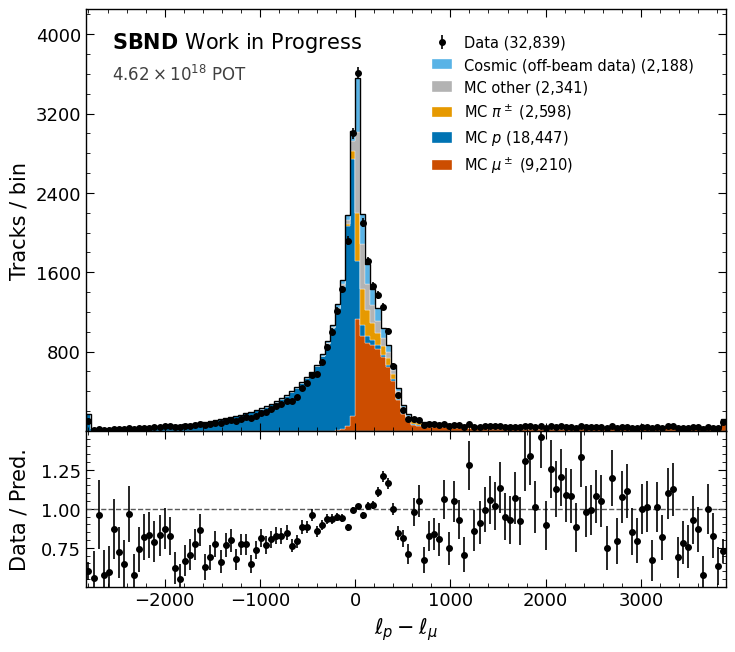

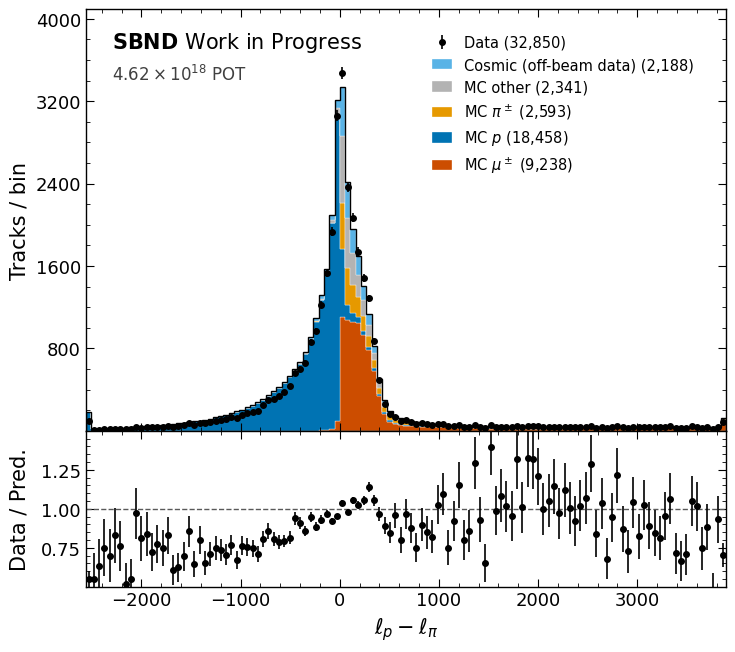

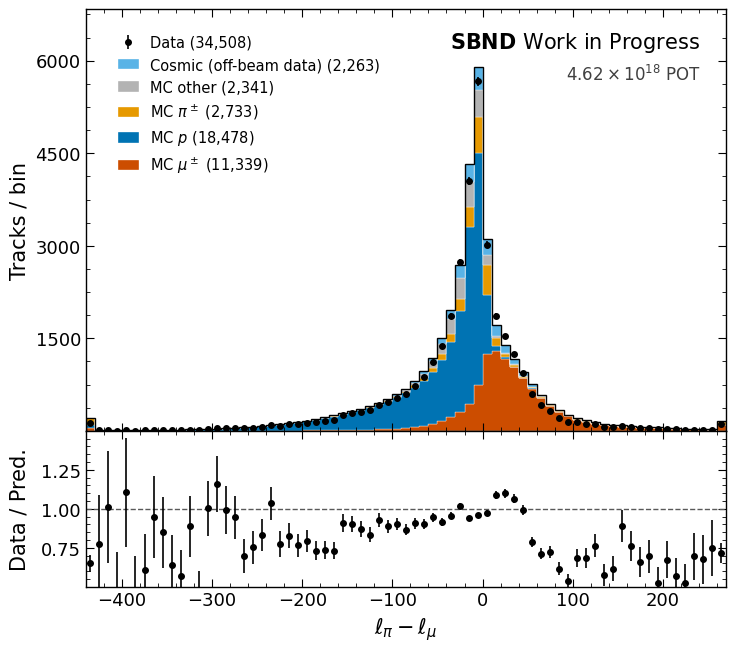

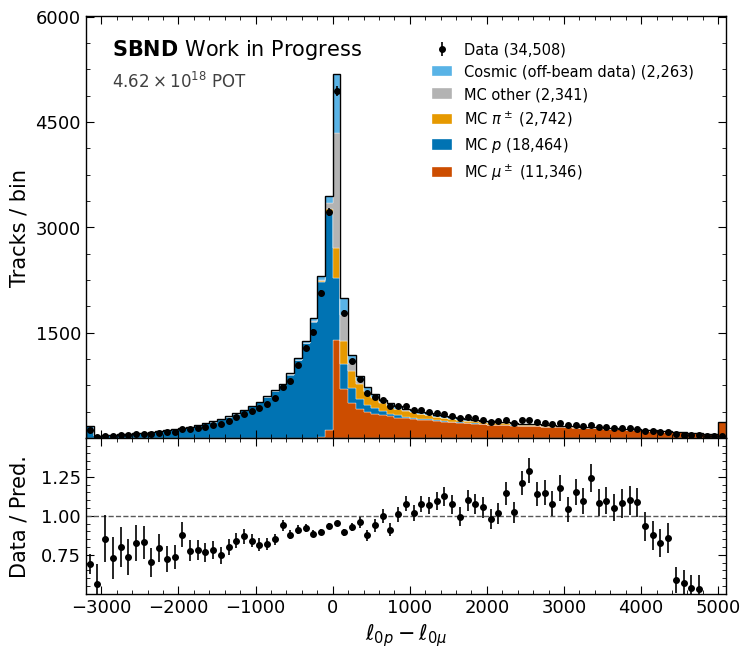

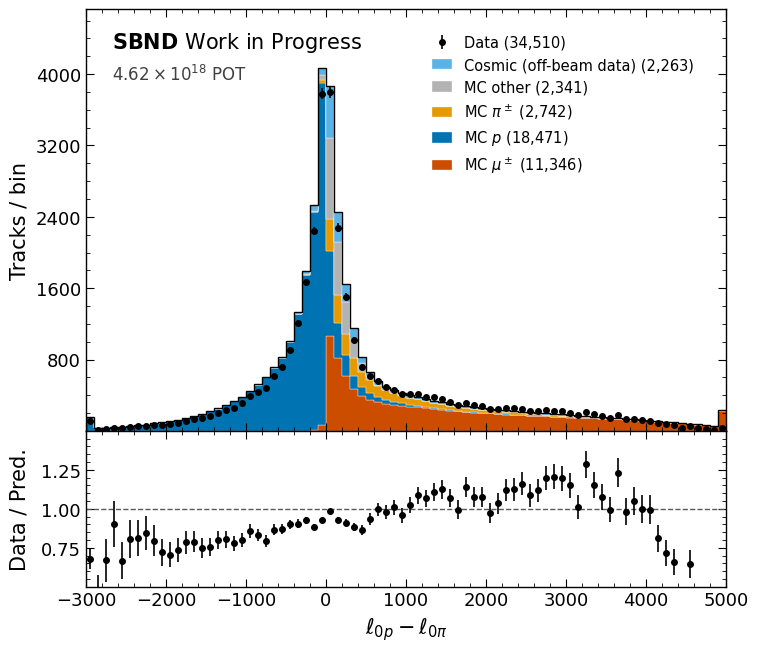

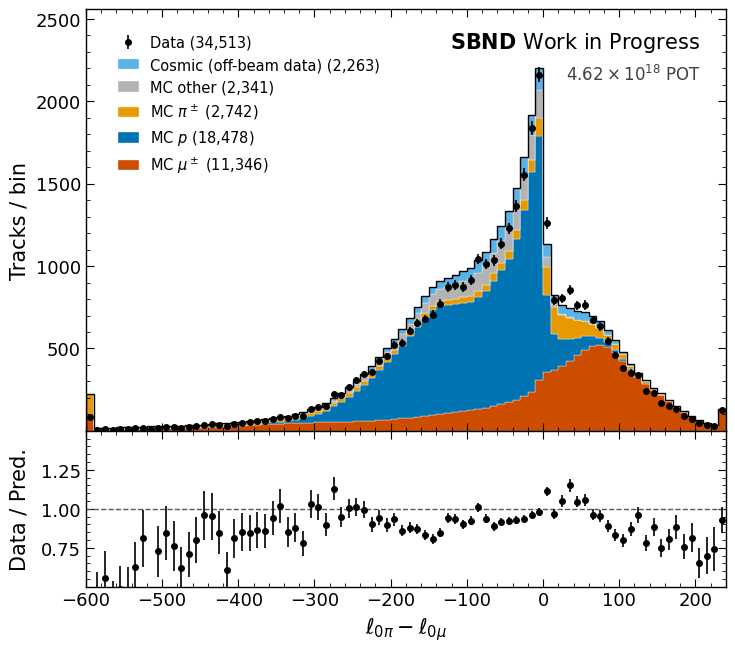

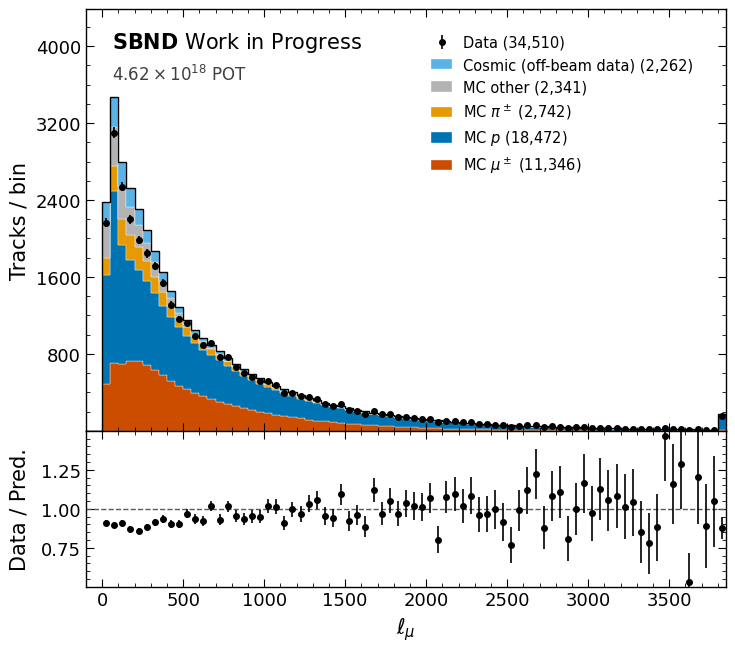

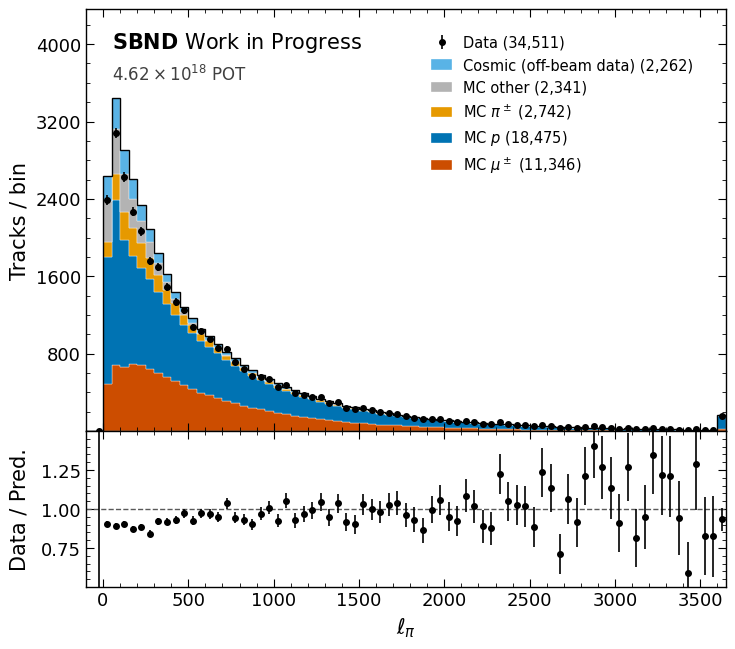

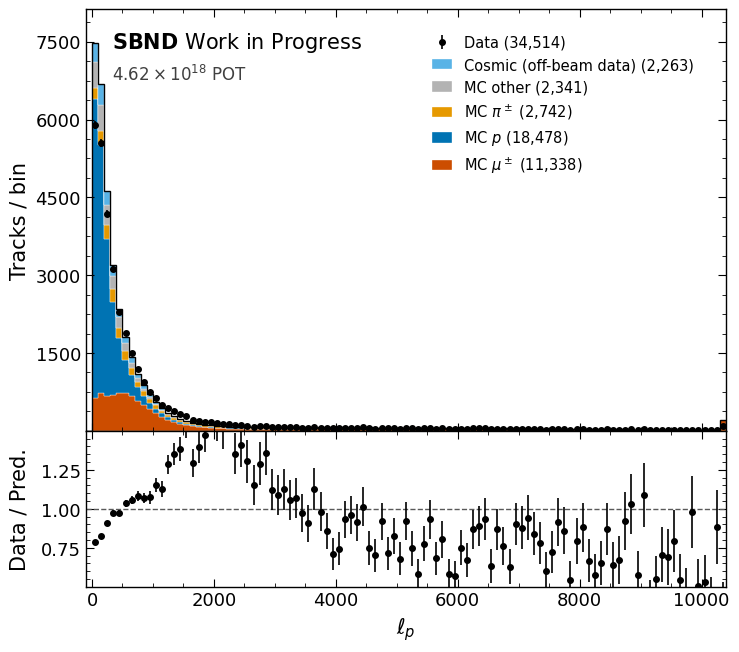

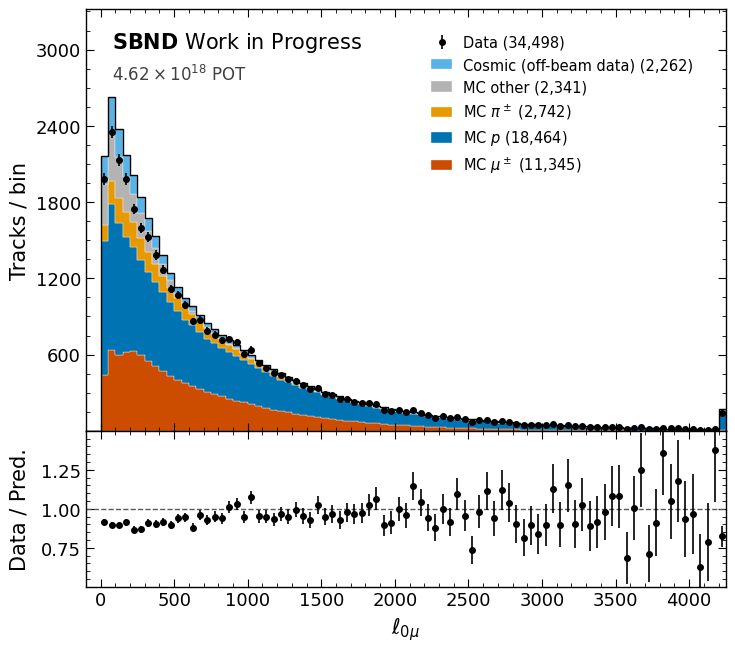

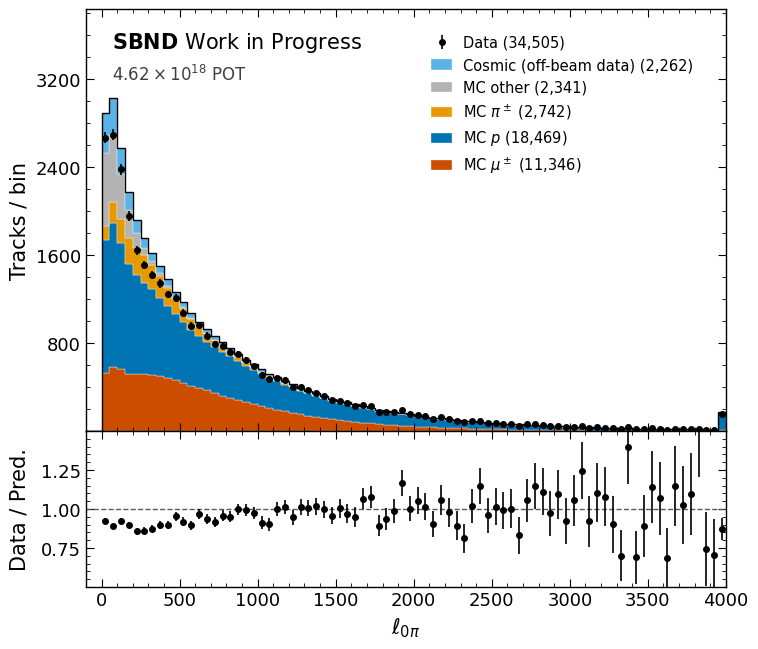

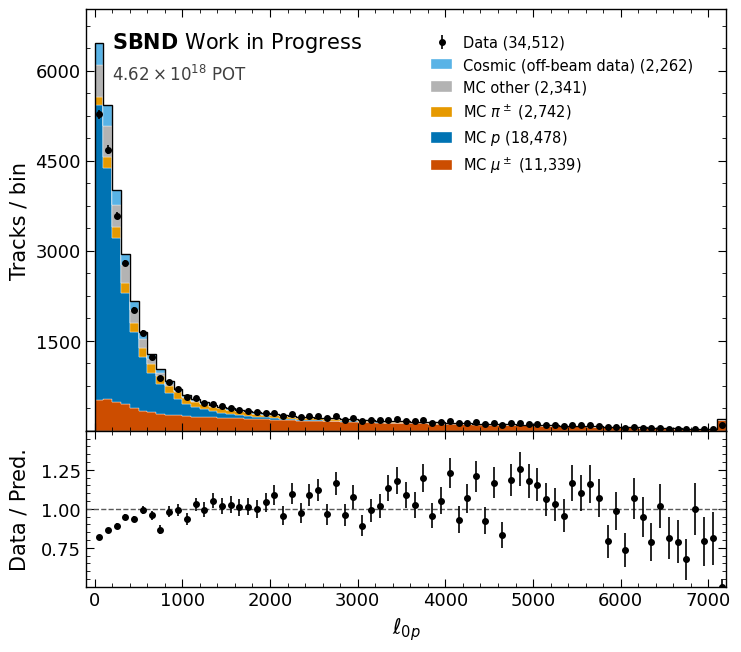

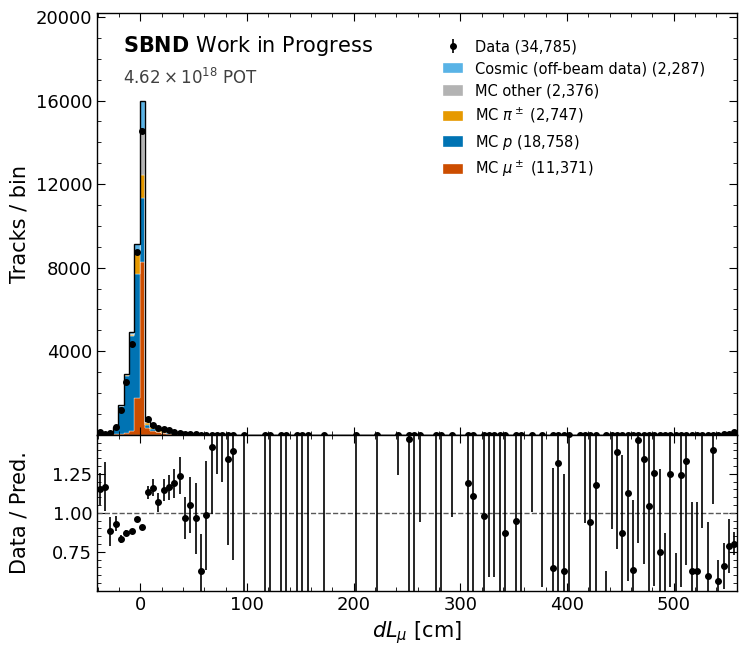

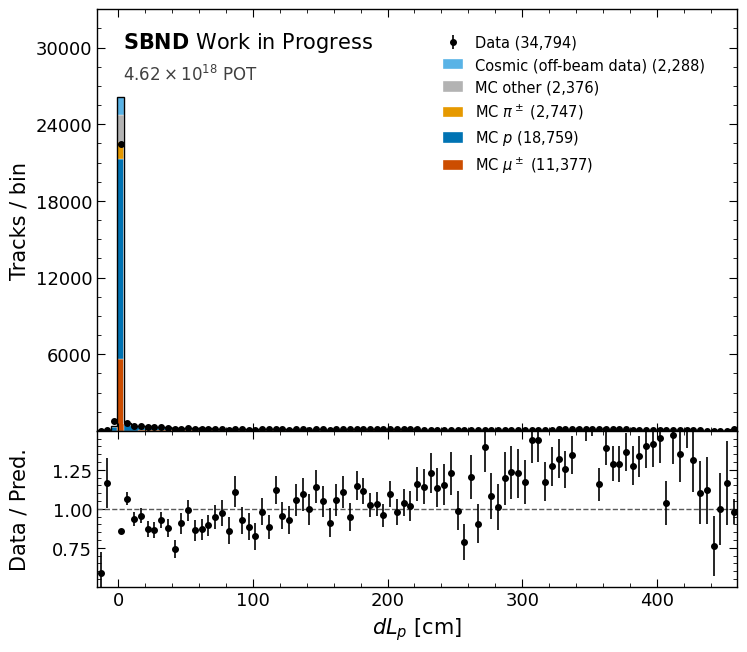

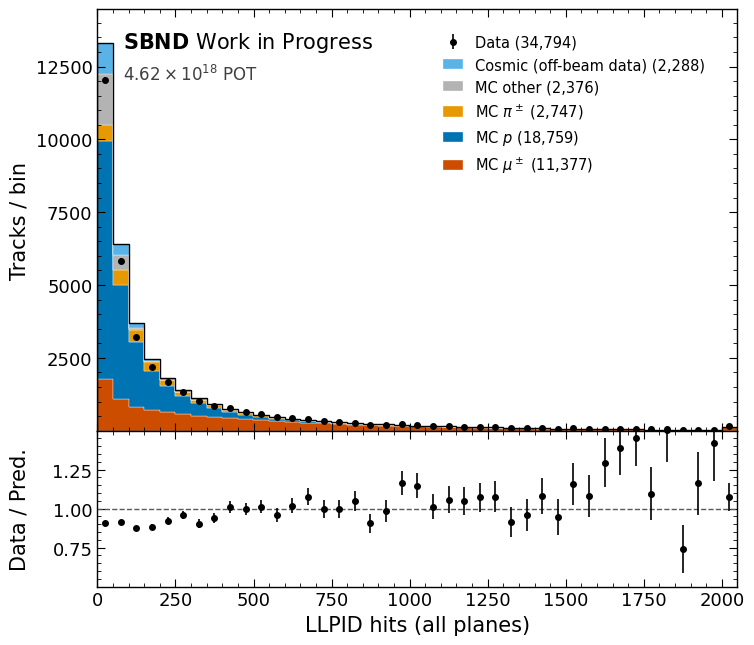

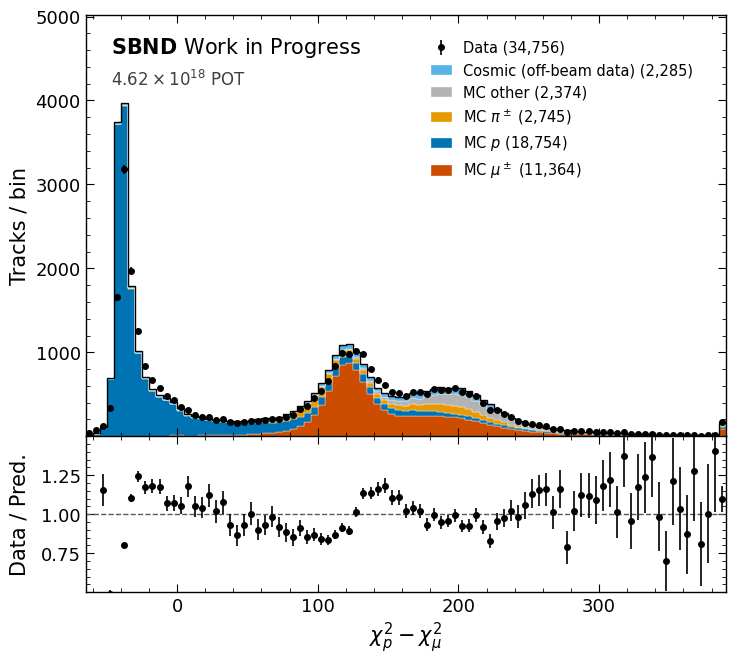

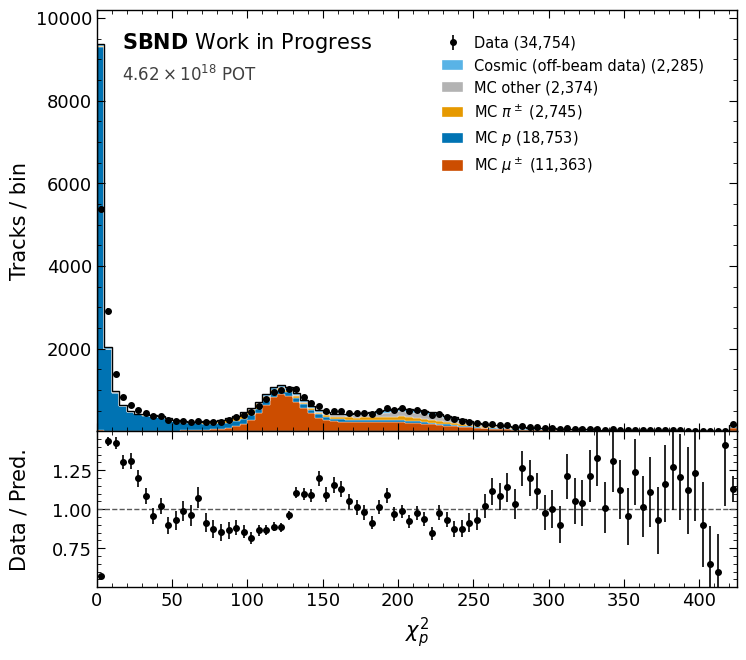

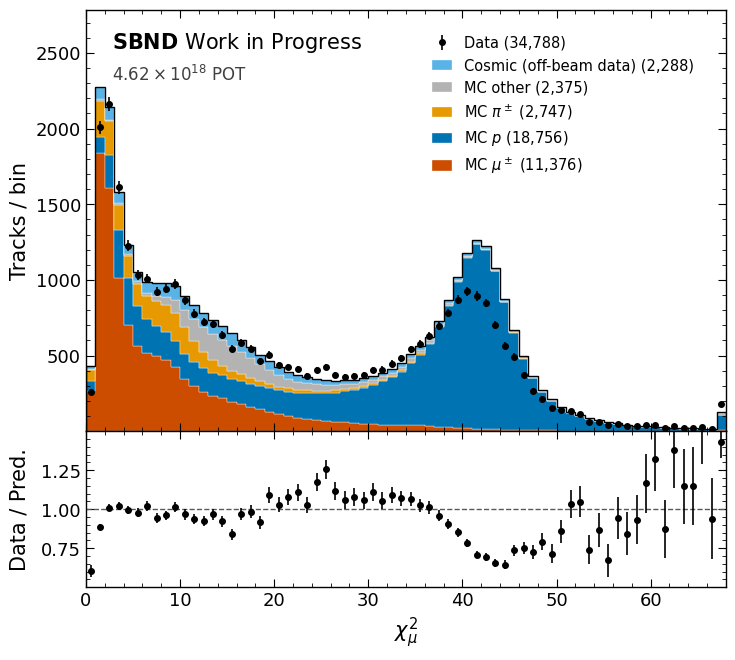

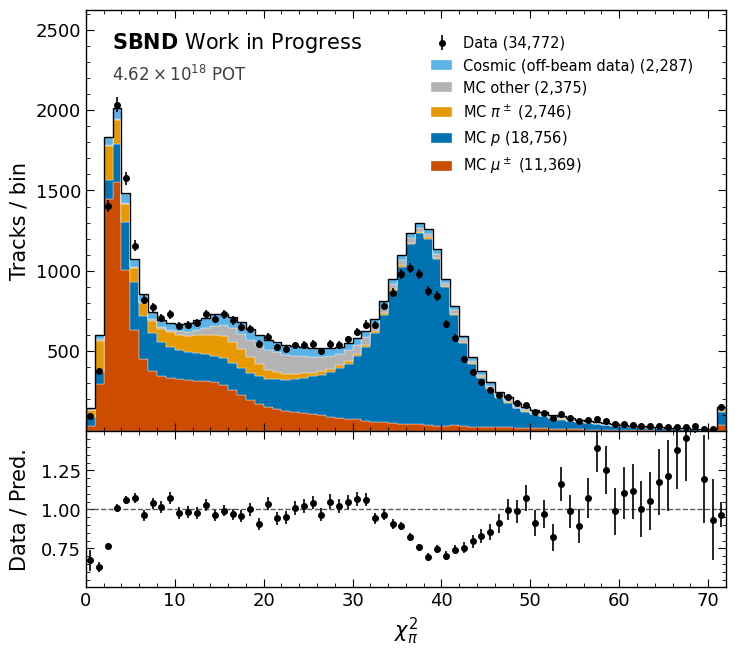

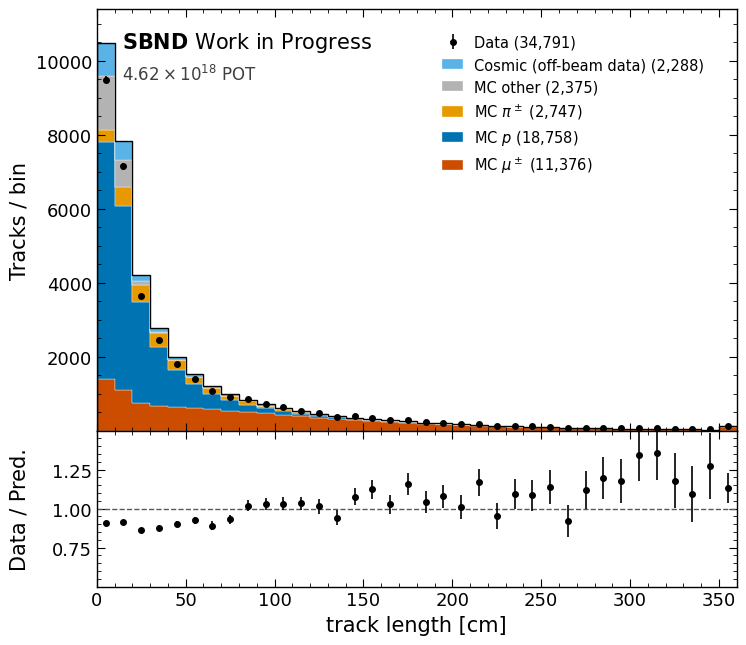

In [63]:
import matplotlib.ticker as mticker
from analysis_village.plot_style import sbnd_style   # applies SBND rcParams on import

OI = sbnd_style.OKABE_ITO_COLORS
STACK = {   # bottom to top
    "muon":   (r"MC $\mu^\pm$",          OI["vermilion"]),
    "proton": (r"MC $p$",                OI["blue"]),
    "pion":   (r"MC $\pi^\pm$",          OI["orange"]),
    "other":  ("MC other",               "0.70"),
    "cosmic": ("Cosmic (off-beam data)", OI["sky_blue"]),
}
plt.rcParams.update({
    "xtick.top": True, "ytick.right": True, "xtick.minor.visible": True, "ytick.minor.visible": True,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.labelsize": 13, "ytick.labelsize": 13,
    "axes.labelsize": 15, "legend.fontsize": 10.5, "hatch.linewidth": 0.6,
})

def pot_label(pot):
    e = int(np.floor(np.log10(pot)))
    return rf"${pot / 10**e:.2f}\times10^{{{e}}}$ POT"

def crop_range(total, lo_q=0.005, hi_q=0.995, pad=2):
    """first/last bin index (exclusive end) holding the central lo_q..hi_q of `total`, plus `pad` bins each side"""
    c = np.cumsum(total) / total.sum()
    i0 = max(np.searchsorted(c, lo_q) - pad, 0)
    i1 = min(np.searchsorted(c, hi_q) + 1 + pad, len(total))
    return i0, i1

def fold(a, i0, i1):
    """keep bins i0:i1, adding everything outside into the first/last kept bin"""
    out = a[i0:i1].copy()
    out[0] += a[:i0].sum()
    out[-1] += a[i1:].sum()
    return out

def fit_headroom(fig, ax, bins, tops, artists, logy, bottom, gap=0.03):
    """raise the y-limit until nothing under any of `artists` (legend, labels) reaches it"""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    to_ax = ax.transAxes.inverted()
    x0, x1 = ax.get_xlim()
    top = tops.max() / 0.92                                    # default headroom
    for art in artists:
        bb = art.get_window_extent(r).transformed(to_ax)       # axes-fraction box
        lo, hi = x0 + bb.x0 * (x1 - x0), x0 + bb.x1 * (x1 - x0)
        under = (bins[1:] >= lo) & (bins[:-1] <= hi)
        if not under.any():
            continue
        peak, f = tops[under].max(), bb.y0 - gap
        if logy:
            top = max(top, bottom * (peak / bottom) ** (1 / f))
        else:
            top = max(top, peak / f)
    ax.set_ylim(bottom, top)

def plot_var(k, logy=False, save=None, crop=True):
    _, bins, xlabel = VARS[k]
    assert len(bins) - 1 == len(H_data[k]["all"]), f"VARS[{k}] changed since filling, refill the histograms"

    # scaled content and sum of w^2 per component (MC and off-beam are unweighted counts x scale)
    comps = {c: (H_mc[k][c] * mc_scale, H_mc[k][c] * mc_scale**2) for c in CATS}
    comps["cosmic"] = (H_off[k]["all"] * offbeam_scale, H_off[k]["all"] * offbeam_scale**2)
    d = H_data[k]["all"]

    if crop:   # zoom on the bulk, fold the tails into the edge bins so no track is lost
        i0, i1 = crop_range(d + sum(v for v, _ in comps.values()))
        bins = bins[i0:i1 + 1]
        comps = {c: (fold(v, i0, i1), fold(w2, i0, i1)) for c, (v, w2) in comps.items()}
        d = fold(d, i0, i1)
    centers = (bins[1:] + bins[:-1]) / 2
    pred = sum(v for v, _ in comps.values())
    pred_err = np.sqrt(sum(w2 for _, w2 in comps.values()))

    fig = plt.figure(figsize=(8, 7.5))
    ax, rax = sbnd_style.split_canvas(fig, ysplit=0.27)

    bottom, handles = np.zeros_like(pred), []
    for c, (v, _) in comps.items():
        label, color = STACK[c]
        handles.append(ax.stairs(bottom + v, bins, baseline=bottom, fill=True, facecolor=color,
                                 edgecolor="white", lw=0.25, label=f"{label} ({v.sum():,.0f})"))
        bottom = bottom + v
    ax.stairs(pred, bins, color="black", lw=1.0)
    m = d > 0
    data = ax.errorbar(centers[m], d[m], yerr=np.sqrt(d[m]), fmt="o", color="black", ms=4,
                       lw=1.2, capsize=0, label=f"Data ({d.sum():,.0f})")

    # ratio panel
    with np.errstate(divide="ignore", invalid="ignore"):
        rel = np.where(pred > 0, pred_err / pred, np.nan)
        r, rerr = d / pred, np.sqrt(d) / pred
    rax.axhline(1, color="0.35", lw=1, ls="--")
    mr = m & (pred > 0)
    rax.errorbar(centers[mr], r[mr], yerr=rerr[mr], fmt="o", color="black", ms=4, lw=1.2, capsize=0)
    rax.set(ylim=(0.5, 1.5), ylabel="Data / Pred.", xlabel=xlabel, xlim=(bins[0], bins[-1]))
    rax.yaxis.set_major_locator(mticker.FixedLocator([0.75, 1.0, 1.25]))
    ax.tick_params(labelbottom=False)
    ax.set_ylabel("Tracks / bin")

    # legend on the emptier side, SBND label on the other
    tops = np.maximum(pred + pred_err, d + np.sqrt(d))
    half = len(tops) // 2
    leg_right = tops[half:].max() <= tops[:half].max()
    lx, tx = (0.97, 0.04) if leg_right else (0.03, 0.96)
    tha = "left" if leg_right else "right"
    t1 = ax.text(tx, 0.95, r"$\bf{SBND}$ Work in Progress", transform=ax.transAxes, va="top", ha=tha, fontsize=15)
    t2 = ax.text(tx, 0.87, pot_label(pot), transform=ax.transAxes, va="top", ha=tha, fontsize=12, color="0.25")
    leg = ax.legend(handles=[data] + handles[::-1] , loc="upper right" if leg_right else "upper left",
                    bbox_to_anchor=(lx, 0.97), handlelength=1.4)

    if logy:
        ax.set_yscale("log")
        floor = 0.5
    else:
        floor = 0
        ax.yaxis.set_major_locator(mticker.MaxNLocator(nbins=6, prune="lower"))
    fit_headroom(fig, ax, bins, tops, [leg, t1, t2], logy, floor)

    fig.align_ylabels([ax, rax])
    if save:
        fig.savefig(save, bbox_inches="tight")
    plt.show()

for k in range(len(H_data)):
    plot_var(k)


true muons / pions / protons: 1329736 321117 2192457
p vs mu, Likelihood              : p efficiency at 1% / 2% / 5% mu mis-ID = 0.869 / 0.940 / 0.962
p vs mu, Likelihood (no rr corr) : p efficiency at 1% / 2% / 5% mu mis-ID = 0.880 / 0.898 / 0.910
p vs mu, Chi2                    : p efficiency at 1% / 2% / 5% mu mis-ID = 0.784 / 0.838 / 0.876
p vs pi, Likelihood              : p efficiency at 1% / 2% / 5% pi mis-ID = 0.897 / 0.934 / 0.951
p vs pi, Likelihood (no rr corr) : p efficiency at 1% / 2% / 5% pi mis-ID = 0.844 / 0.889 / 0.905
p vs pi, Chi2                    : p efficiency at 1% / 2% / 5% pi mis-ID = 0.754 / 0.805 / 0.846
mu vs pi, Likelihood              : mu efficiency at 1% / 2% / 5% pi mis-ID = 0.002 / 0.007 / 0.040
mu vs pi, Likelihood (no rr corr) : mu efficiency at 1% / 2% / 5% pi mis-ID = 0.108 / 0.157 / 0.265
mu vs pi, Chi2                    : mu efficiency at 1% / 2% / 5% pi mis-ID = 0.014 / 0.029 / 0.074


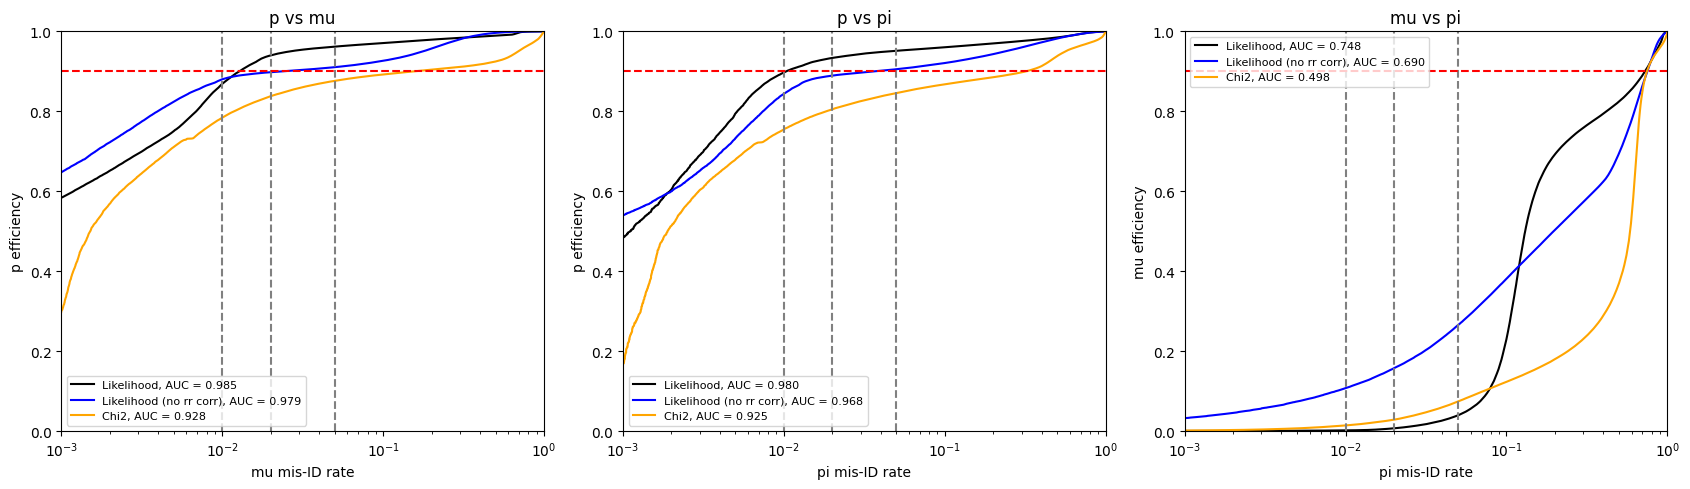

In [26]:
perf = []
for f in sorted(glob.glob(SKIM + "llpid_skim_mc_*.h5")):
    d = pd.read_hdf(f, "evt")
    d = d[selection(d)]
    perf.append(d[np.abs(d["pfp", "trk", "truth", "p", "pdg"]).isin([13, 211, 2212])])
perf = pd.concat(perf)
true = np.abs(perf["pfp", "trk", "truth", "p", "pdg"]).to_numpy()
print("true muons / pions / protons:", np.sum(true == 13), np.sum(true == 211), np.sum(true == 2212))

def roc(sig, bkg):
    """signal efficiency vs background mis-ID when selecting score <= cut"""
    sig, bkg = np.sort(sig[~np.isnan(sig)]), np.sort(bkg[~np.isnan(bkg)])
    cut = np.quantile(np.concatenate([sig, bkg]), np.linspace(0, 1, 2001))
    return np.searchsorted(bkg, cut, side="right") / len(bkg), np.searchsorted(sig, cut, side="right") / len(sig)

PDG = {"mu": 13, "pi": 211, "p": 2212}
CHI_NAME = {"mu": "chi2_muon", "pi": "chi2_pion", "p": "chi2_proton"}
SCORES = {
    "Likelihood":              lambda d, a, b: LL(d, "ell_" + a) - LL(d, "ell_" + b),
    "Likelihood (no rr corr)": lambda d, a, b: LL(d, "ell0_" + a) - LL(d, "ell0_" + b),
    "Chi2":                    lambda d, a, b: CHI(d, CHI_NAME[a]) - CHI(d, CHI_NAME[b]),
}

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for i, (a, b) in enumerate([("p", "mu"), ("p", "pi"), ("mu", "pi")]):
    for (name, score), color in zip(SCORES.items(), ["black", "blue", "orange"]):
        s = score(perf, a, b).to_numpy()
        bkg_eff, sig_eff = roc(s[true == PDG[a]], s[true == PDG[b]])
        ax[i].plot(bkg_eff, sig_eff, color=color, label=f"{name}, AUC = {np.trapz(sig_eff, bkg_eff):.3f}")
        print(f"{a} vs {b}, {name:24s}: {a} efficiency at 1% / 2% / 5% {b} mis-ID = "
              + " / ".join(f"{np.interp(x, bkg_eff, sig_eff):.3f}" for x in [0.01, 0.02, 0.05]))
    ax[i].set(title=f"{a} vs {b}", xlabel=f"{b} mis-ID rate", ylabel=f"{a} efficiency", xscale="log", xlim=(1e-3, 1), ylim=(0, 1))
    ax[i].vlines([0.01, 0.02, 0.05], color="gray", ymin=0, ymax=1, ls="--")
    ax[i].hlines(0.9, xmin=1e-3, xmax=1, color="red", ls="--")
    # ax[i].set(title=f"{a} vs {b}", xlabel=f"{b} mis-ID rate", ylabel=f"{a} efficiency")
    ax[i].legend(fontsize=8)
plt.tight_layout()
plt.show()


true muons / pions / protons: 989816 168262 1070157
p vs mu, Likelihood                : cut      4.05 -> p efficiency 0.951 at 2% mu mis-ID
p vs mu, Likelihood (no RR corr.)  : cut      11.6 -> p efficiency 0.908 at 2% mu mis-ID
p vs mu, $\chi^2$                  : cut      68.8 -> p efficiency 0.859 at 2% mu mis-ID
p vs pi, Likelihood                : cut    -0.149 -> p efficiency 0.936 at 2% pi mis-ID
p vs pi, Likelihood (no RR corr.)  : cut      3.78 -> p efficiency 0.894 at 2% pi mis-ID
p vs pi, $\chi^2$                  : cut      36.2 -> p efficiency 0.808 at 2% pi mis-ID
pi vs mu, Likelihood                : cut      -102 -> pi efficiency 0.070 at 2% mu mis-ID
pi vs mu, Likelihood (no RR corr.)  : cut      -463 -> pi efficiency 0.093 at 2% mu mis-ID
pi vs mu, $\chi^2$                  : cut     -1.23 -> pi efficiency 0.046 at 2% mu mis-ID


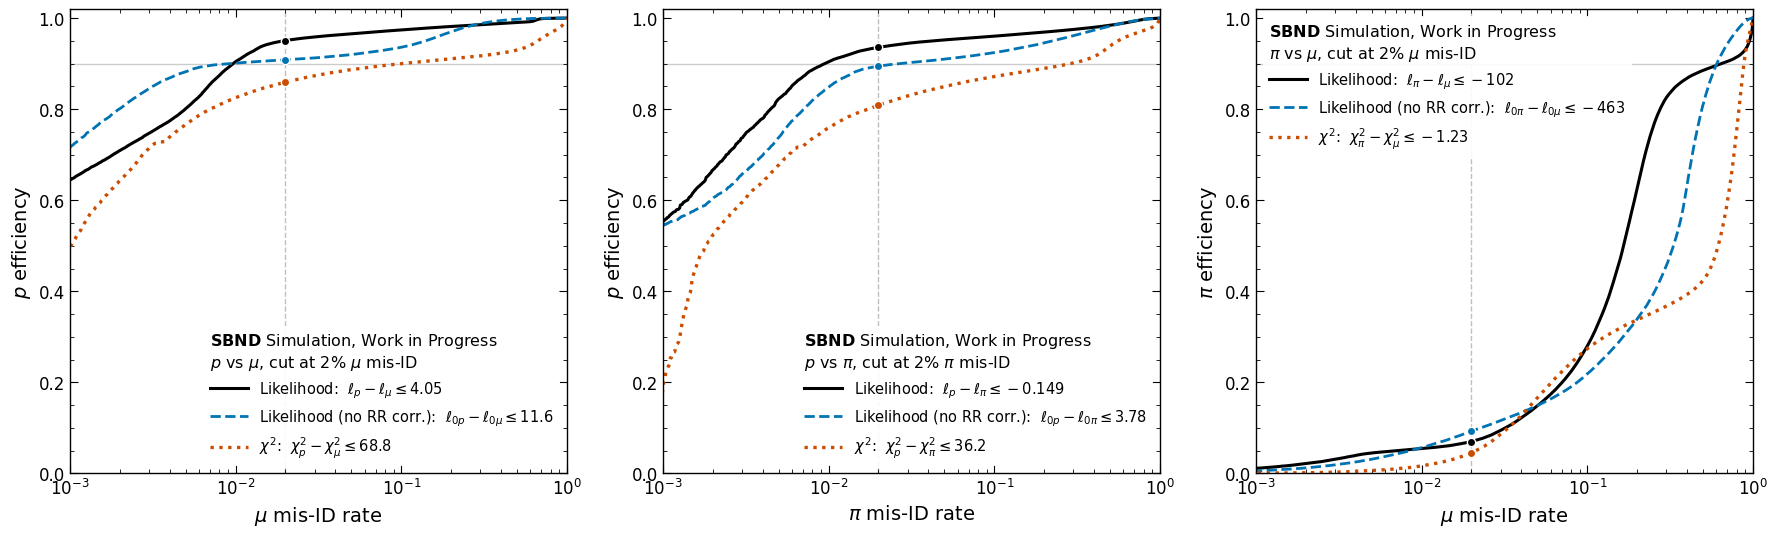

In [67]:
import matplotlib.ticker as mticker
OI = sbnd_style.OKABE_ITO_COLORS

# one common sample: tracks where both the likelihood and chi2 PID ran, so every curve uses the same tracks
perf = truth[valid_chi(truth) & LL(truth, "ell_mu").notna()]
true = np.abs(perf["pfp", "trk", "truth", "p", "pdg"]).to_numpy()
print("true muons / pions / protons:", np.sum(true == 13), np.sum(true == 211), np.sum(true == 2212))

PDG = {"mu": 13, "pi": 211, "p": 2212}
NICE = {"mu": r"\mu", "pi": r"\pi", "p": "p"}
CHI_NAME = {"mu": "chi2_muon", "pi": "chi2_pion", "p": "chi2_proton"}
SCORES = {   # name: (score function, cut variable as a function of the two hypotheses)
    "Likelihood":               (lambda d, a, b: LL(d, "ell_" + a) - LL(d, "ell_" + b),
                                 lambda a, b: rf"\ell_{{{a}}} - \ell_{{{b}}}"),
    "Likelihood (no RR corr.)": (lambda d, a, b: LL(d, "ell0_" + a) - LL(d, "ell0_" + b),
                                 lambda a, b: rf"\ell_{{0{a}}} - \ell_{{0{b}}}"),
    r"$\chi^2$":                (lambda d, a, b: CHI(d, CHI_NAME[a]) - CHI(d, CHI_NAME[b]),
                                 lambda a, b: rf"\chi^2_{{{a}}} - \chi^2_{{{b}}}"),
}
STYLE = {   # colour + line style so the curves stay distinct without colour
    "Likelihood":               dict(color="black",         ls="-",  lw=2.2),
    "Likelihood (no RR corr.)": dict(color=OI["blue"],      ls="--", lw=2.0),
    r"$\chi^2$":                dict(color=OI["vermilion"], ls=":",  lw=2.4),
}
WP = 0.02   # mis-ID working point quoted in the legend

def roc(sig, bkg):
    """exact ROC selecting score <= cut: (background mis-ID, signal efficiency) at every threshold"""
    sig, bkg = sig[np.isfinite(sig)], bkg[np.isfinite(bkg)]
    y = np.r_[np.ones(len(sig)), np.zeros(len(bkg))][np.argsort(np.r_[sig, bkg], kind="stable")]
    return np.r_[0, np.cumsum(1 - y) / len(bkg)], np.r_[0, np.cumsum(y) / len(sig)]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
grid = np.geomspace(1e-4, 1, 800)   # plotting grid; the full curve is used for the working point
for ax, (a, b) in zip(axes, [("p", "mu"), ("p", "pi"), ("pi", "mu")]):
    high = False
    for name, (score, sym) in SCORES.items():
        s = np.asarray(score(perf, a, b), float)
        sig, bkg = s[true == PDG[a]], s[true == PDG[b]]
        fpr, tpr = roc(sig, bkg)
        cut = np.quantile(bkg[np.isfinite(bkg)], WP)   # selecting score <= cut keeps WP of the background
        eff = np.interp(WP, fpr, tpr)
        high |= eff > 0.5
        ax.plot(grid, np.interp(grid, fpr, tpr), **STYLE[name], label=rf"{name}:  ${sym(NICE[a], NICE[b])} \leq {cut:.3g}$")
        ax.plot(WP, eff, "o", color=STYLE[name]["color"], ms=6, mec="white", mew=1, zorder=5)
        print(f"{a} vs {b}, {name:26s}: cut {cut:9.3g} -> {a} efficiency {eff:.3f} at {100 * WP:.0f}% {b} mis-ID")
    ax.axvline(WP, color="0.75", lw=1, ls="--", zorder=0)
    ax.set(xscale="log", xlim=(1e-3, 1), ylim=(0, 1.02),
           xlabel=rf"${NICE[b]}$ mis-ID rate", ylabel=rf"${NICE[a]}$ efficiency")
    ax.yaxis.set_major_locator(mticker.MultipleLocator(0.2))
    ax.axhline(0.9, color="0.8", lw=1, zorder=0)

    ax.tick_params(which="both", top=True, right=True, direction="in", labelsize=12)
    ax.xaxis.label.set_size(14); ax.yaxis.label.set_size(14)
    # curves high -> lower right is empty; curves low -> upper left is empty
    ax.legend(loc="lower right" if high else "upper left", fontsize=10.5, handlelength=2.6,
              title=(r"$\bf{SBND}$ Simulation, Work in Progress" + "\n"
                     + rf"${NICE[a]}$ vs ${NICE[b]}$, cut at {100 * WP:.0f}% ${NICE[b]}$ mis-ID"),
              title_fontsize=11.5, alignment="left", frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
fig.tight_layout()
plt.show()


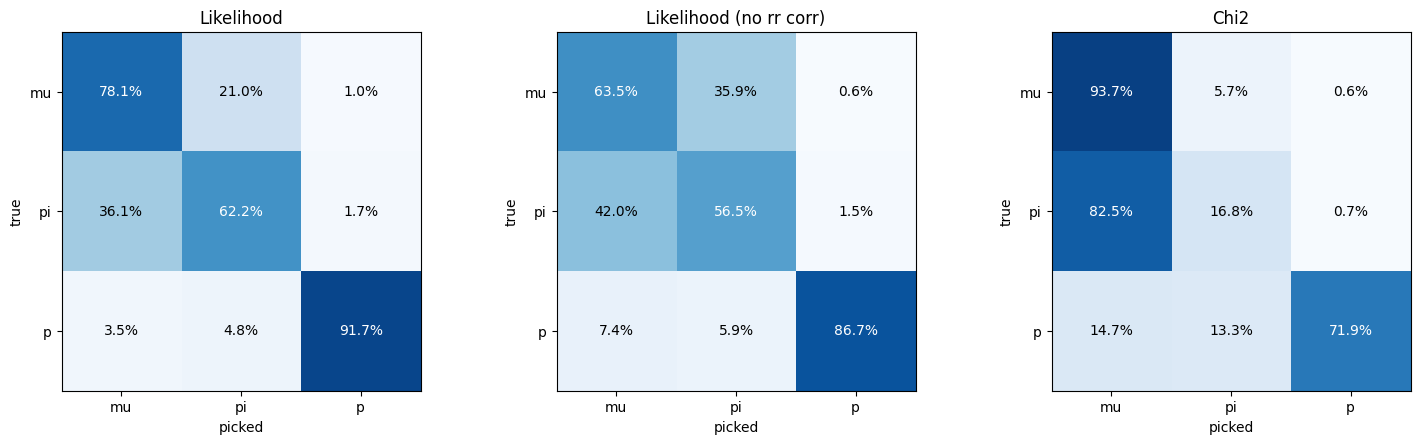

In [27]:
HYPS = ["mu", "pi", "p"]
best = {
    "Likelihood":              np.argmin(np.column_stack([LL(perf, "ell_" + h) for h in HYPS]), axis=1),
    "Likelihood (no rr corr)": np.argmin(np.column_stack([LL(perf, "ell0_" + h) for h in HYPS]), axis=1),
    "Chi2":                    np.argmin(np.column_stack([CHI(perf, CHI_NAME[h]) for h in HYPS]), axis=1),
}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for k, (name, pick) in enumerate(best.items()):
    mat = np.array([[np.mean(pick[true == PDG[t]] == j) for j in range(3)] for t in HYPS])
    ax[k].imshow(mat, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax[k].text(j, i, f"{100 * mat[i, j]:.1f}%", ha="center", va="center", color="white" if mat[i, j] > 0.5 else "black")
    ax[k].set(title=name, xticks=range(3), yticks=range(3), xticklabels=HYPS, yticklabels=HYPS, xlabel="picked", ylabel="true")
plt.tight_layout()
plt.show()


In [44]:
SLICE = ["file", "__ntuple", "entry", "rec.slc..index"]

def trk_contained(df):
    """track start and end inside the Gen 1 volume and in the same TPC as the slice vertex"""
    s = [df["pfp", "trk", "start", c] for c in "xyz"]
    e = [df["pfp", "trk", "end", c] for c in "xyz"]
    tpc = np.sign(df["slc", "vertex", "x"])
    return in_volume(*s) & in_volume(*e) & (np.sign(s[0]) == tpc) & (np.sign(e[0]) == tpc)

def valid_chi(df):
    c = df["pfp", "trk", "chi2pid", "I2"]
    return (c["chi2_proton"] != 0) & (c["chi2_muon"] != 0) & (c["chi2_pion"] != 0)

def event_selection(df):
    """slice-level cuts, every PFP row in a slice passes or fails together"""
    no_trk = df["pfp", "trk", "len"].isna()
    all_contained = (trk_contained(df) | no_trk).groupby(level=SLICE).transform("all")
    return (in_fv(df)
            & (df["slc", "is_clear_cosmic"] == 0)
            & (df["slc", "barycenterFM", "flashPEs"] > 3000)
            & all_contained)

def track_selection(df):
    return ((df["pfp", "trk", "len"] > 6)
            & (df["pfp", "trackScore"] > 0.5)
            & (df["pfp", "dist_to_vertex"] < 6))

def selection(df, require_chi=True):
    sel = event_selection(df) & track_selection(df)
    return sel & valid_chi(df) if require_chi else sel


In [40]:
import gc
from matplotlib.colors import LogNorm

TRUTH_COLS = [("pfp", "trk", "llpid"), ("pfp", "trk", "chi2pid", "I2"), ("pfp", "trk", "truth", "p"),
              ("pfp", "trk", "rangeP"), ("pfp", "trk", "len")]

truth = []
for f in sorted(glob.glob(SKIM + "llpid_skim_mc_*.h5")):
    d = pd.read_hdf(f, "evt")
    d = d[selection(d, require_chi=False)]
    d = d[np.abs(d["pfp", "trk", "truth", "p", "pdg"]).isin([13, 211, 2212])]
    truth.append(d[[c for c in d.columns if any(c[:len(k)] == k for k in TRUTH_COLS)]])
    del d
    gc.collect()
truth = pd.concat(truth)
print(f"truth-matched mu/pi/p tracks: {len(truth)}")


truth-matched mu/pi/p tracks: 2331600


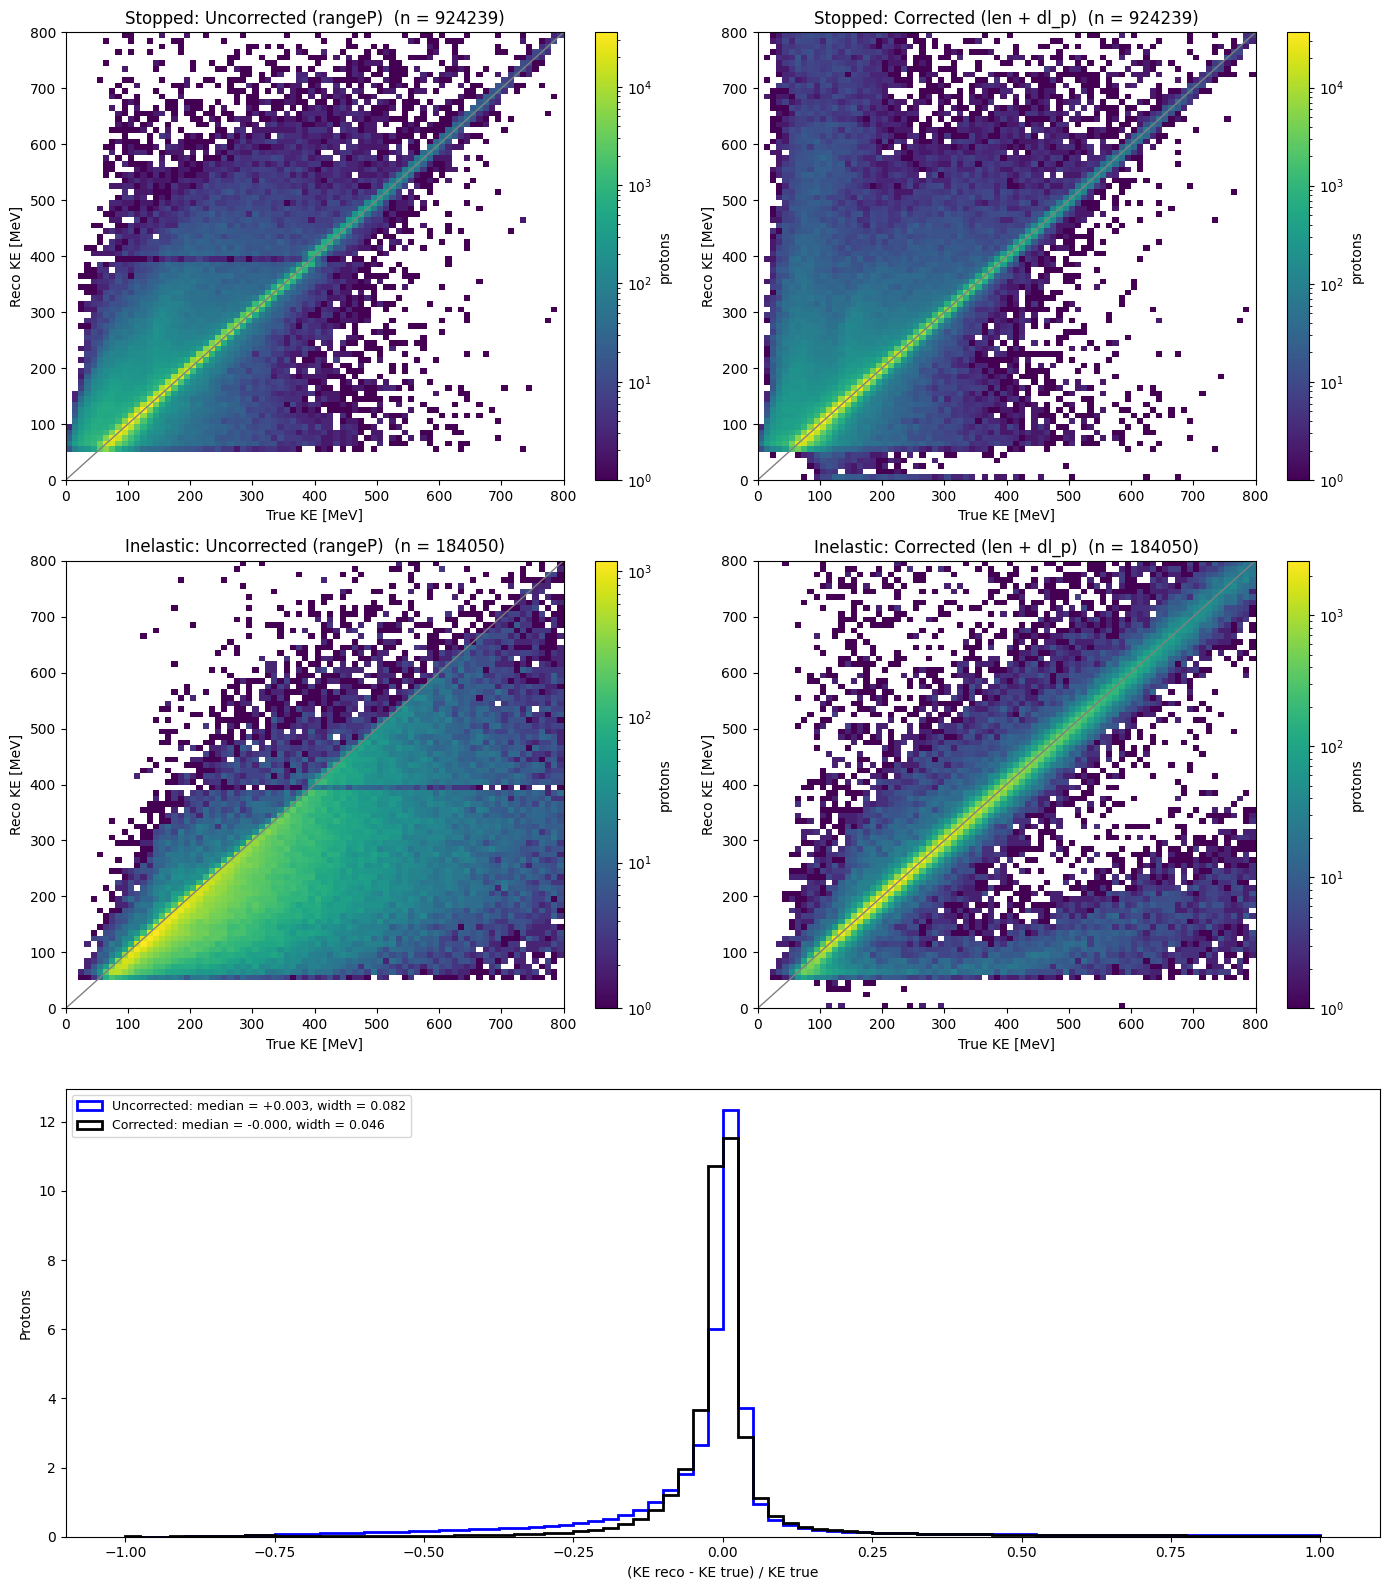

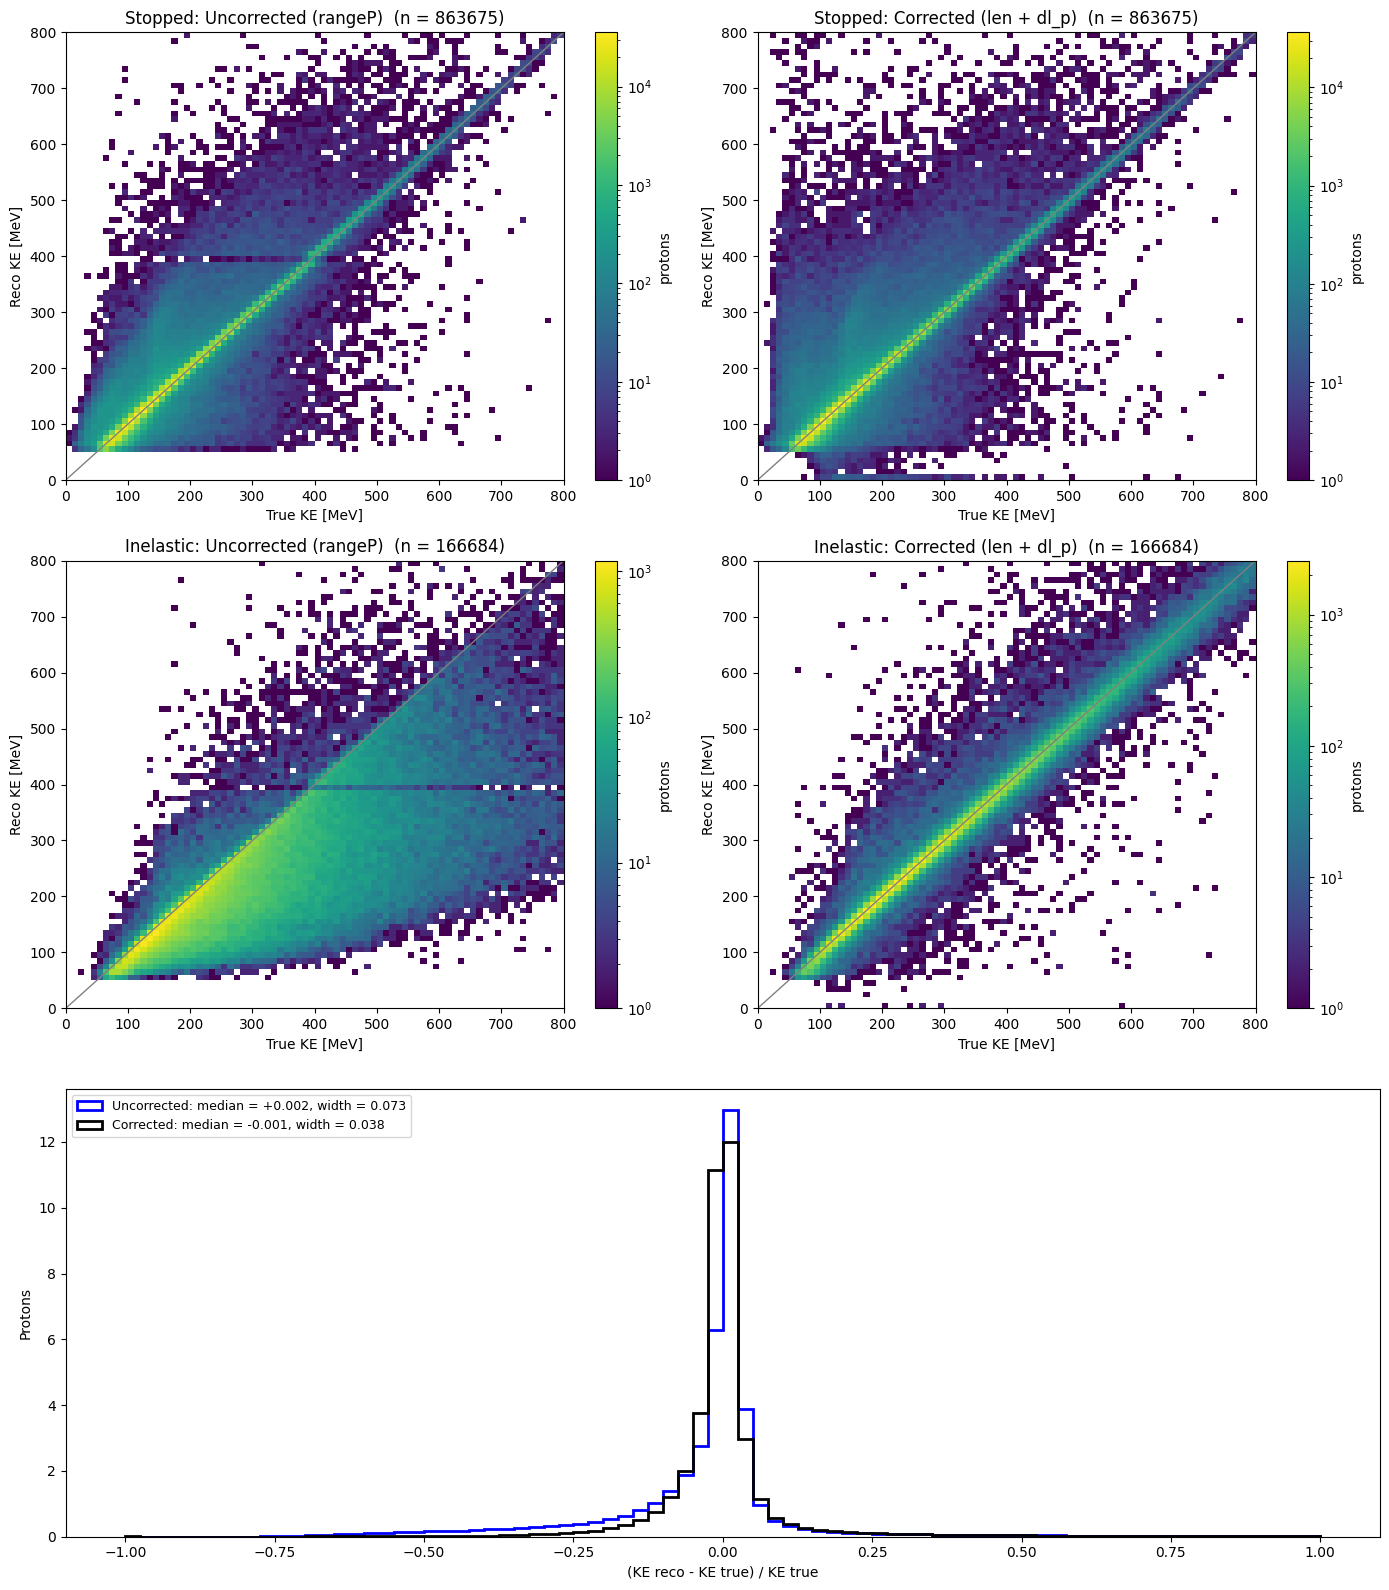

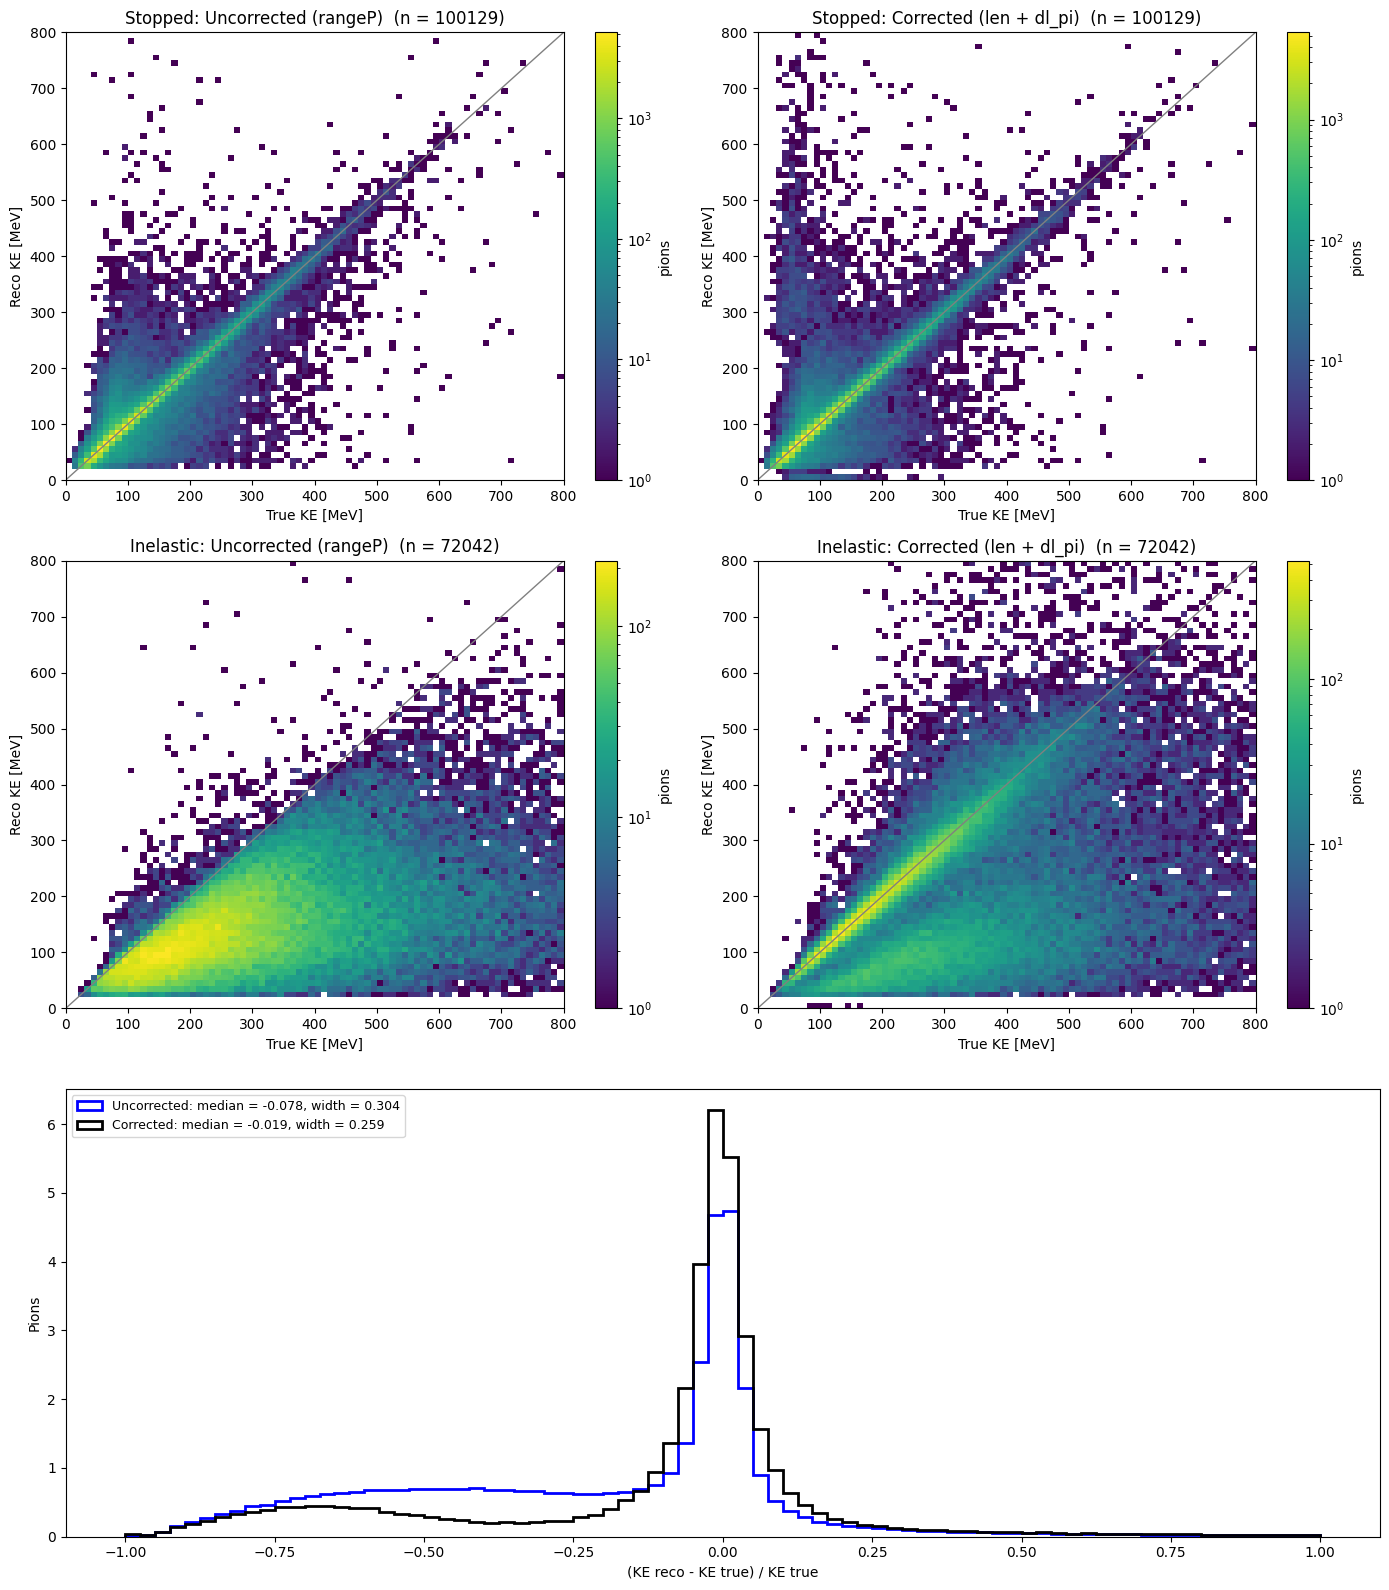

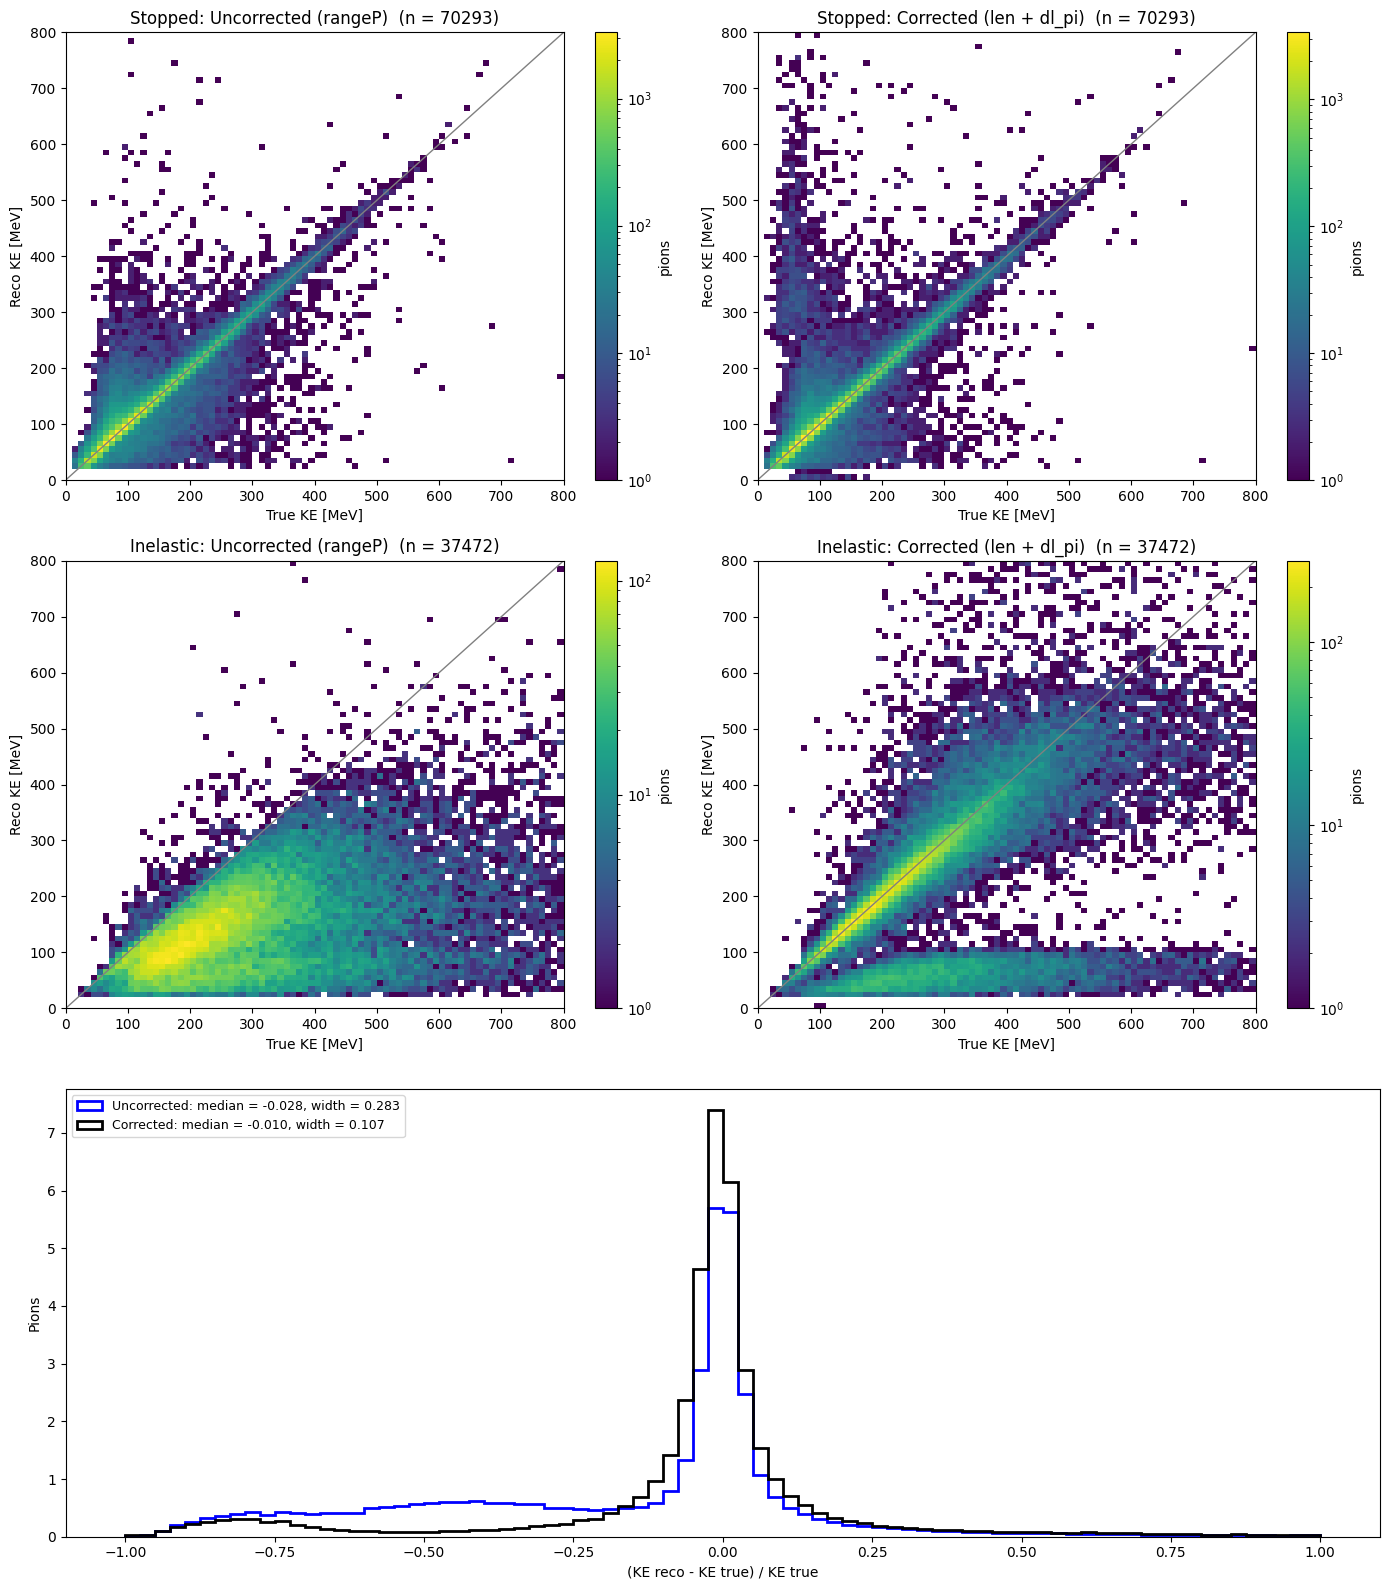

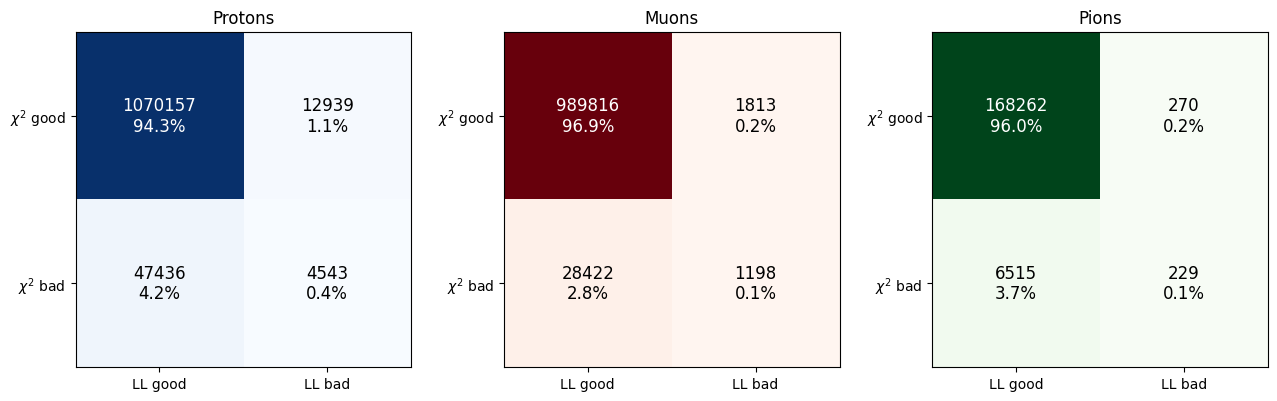

In [46]:
PDGS    = {"p": 2212, "pi": 211}
MASS    = {"p": 0.938272, "pi": 0.13957039}   # GeV
RANGEP  = {"p": "p_proton", "pi": "p_pion"}
STOPPED = {"p": [54], "pi": [3, 45]}           # hIoni / Decay, CaptureAtRest
INEL    = {"p": [7],  "pi": [9, 10]}           # protonInelastic / pi+-Inelastic
NAME    = {"p": "Protons", "pi": "Pions"}

def ke_panels(df, h, ke_max=800, nbins=80, pid=False):
    d = df[(np.abs(df["pfp", "trk", "truth", "p", "pdg"]) == PDGS[h])
           & (df["pfp", "trk", "truth", "p", "cont_tpc"] == 1)
           & df["pfp", "trk", "llpid", "ell_" + h].notna()]
    if pid:   # only tracks the likelihood identifies as hypothesis h
        ell = d["pfp", "trk", "llpid"][["ell_mu", "ell_pi", "ell_p"]]
        d = d[ell.idxmin(axis=1) == ("ell_" + h, "", "")]
    m = MASS[h]
    ke_true = ((d["pfp", "trk", "truth", "p", "startE"] - m) * 1000).to_numpy()
    p_range = d["pfp", "trk", "rangeP", RANGEP[h]].to_numpy()
    ke_unc = (np.sqrt(p_range**2 + m**2) - m) * 1000
    table = llpid._ke_table(h)
    ke_cor = np.interp(d["pfp", "trk", "len"] + d["pfp", "trk", "llpid", "dl_" + h], table["range"], table["ke"])
    ep = d["pfp", "trk", "truth", "p", "end_process"]
    groups = {"Stopped": ep.isin(STOPPED[h]).to_numpy(), "Inelastic": ep.isin(INEL[h]).to_numpy()}
    recos = {"Uncorrected (rangeP)": ke_unc, f"Corrected (len + dl_{h})": ke_cor}

    fig = plt.figure(figsize=(14, 16))
    gs = fig.add_gridspec(3, 2)
    edges = np.linspace(0, ke_max, nbins + 1)
    for i, (gname, g) in enumerate(groups.items()):
        for j, (rname, ke) in enumerate(recos.items()):
            a = fig.add_subplot(gs[i, j])
            *_, im = a.hist2d(ke_true[g], ke[g], bins=edges, norm=LogNorm(), cmap="viridis")
            fig.colorbar(im, ax=a, label=NAME[h].lower())
            a.plot([0, ke_max], [0, ke_max], color="gray", lw=1)
            a.set(title=f"{gname}: {rname}  (n = {g.sum()})", xlabel="True KE [MeV]", ylabel="Reco KE [MeV]")

    rax = fig.add_subplot(gs[2, :])
    for (rname, ke), color in zip(recos.items(), ["blue", "black"]):
        res = (ke - ke_true) / ke_true
        res = res[np.isfinite(res)]
        width = (np.percentile(res, 84) - np.percentile(res, 16)) / 2
        rax.hist(res, bins=np.linspace(-1, 1, 81), histtype="step", lw=2, color=color, label=f"{rname.split(' ')[0]}: median = {np.median(res):+.3f}, width = {width:.3f}", density=True)
    rax.set(xlabel="(KE reco - KE true) / KE true", ylabel=NAME[h])
    rax.legend(loc="upper left", fontsize=9)
    plt.tight_layout()
    plt.show()


def fail_matrices(df):
    """rows = chi2 (good, bad), columns = llpid (good, bad)"""
    pdg = np.abs(df["pfp", "trk", "truth", "p", "pdg"])
    fig, ax = plt.subplots(1, 3, figsize=(13, 4))
    for a, (name, code, cmap) in zip(ax, [("Protons", 2212, "Blues"), ("Muons", 13, "Reds"), ("Pions", 211, "Greens")]):
        d = df[pdg == code]
        ll_bad  = d["pfp", "trk", "llpid", "ell_mu"].isna().to_numpy()
        chi2 = d["pfp", "trk", "chi2pid", "I2"][["chi2_proton", "chi2_muon", "chi2_pion"]]
        chi_bad = (chi2 == 0).any(axis=1).to_numpy()
        mat = np.array([[np.sum(~chi_bad & ~ll_bad), np.sum(~chi_bad & ll_bad)],
                        [np.sum(chi_bad & ~ll_bad),  np.sum(chi_bad & ll_bad)]])
        a.imshow(mat, cmap=cmap)
        for i in range(2):
            for j in range(2):
                a.text(j, i, f"{mat[i, j]}\n{100 * mat[i, j] / mat.sum():.1f}%", ha="center", va="center", fontsize=12,
                       color="white" if mat[i, j] > mat.max() / 2 else "black")
        a.set(title=name, xticks=[0, 1], yticks=[0, 1], xticklabels=["LL good", "LL bad"],
              yticklabels=[r"$\chi^2$ good", r"$\chi^2$ bad"])
    plt.tight_layout()
    plt.show()


ke_panels(truth, "p")
ke_panels(truth, "p", pid=True)
ke_panels(truth, "pi")
ke_panels(truth, "pi", pid=True)
fail_matrices(truth)
